![Logo Javeriana](https://images.seeklogo.com/logo-png/11/1/pontificia-universidad-javeriana-logo-png_seeklogo-110703.png)

## Nombres:
- Gabriel Jaramillo Cuberos (Id: 20529022)
- David Vargas (Id: 20485686)
- Juan Felipe Gómez López (Id: 20553416)
- Sara Pulgarín (Id: 20491129)
- Juan Camilo Delgado (Id: 20506996)

*Materia:* Procesamiento de Datos (1255)  |  *Tema:* Consultoría Nueva York

*Descripción:* Análisis exploratorio de los arrestos de Nueva York en 2018 para caracterizar su distribución por distrito y período, y la composición de las categorías de arresto entre territorios y meses.

*Nombre del fichero:* Arrestos_P1-P2.ipynb

# Arrestos en Nueva York 2018 — Distribución territorial-temporal y composición de categorías

## Objetivos del cuaderno

Responder, con evidencia descriptiva y agregaciones auditables, las dos preguntas de seguridad pública:

1. ¿Cómo se distribuyen los arrestos por territorio y período durante el año disponible?
2. ¿Cómo cambia la composición de las categorías de arresto entre territorios y períodos?

Objetivos específicos:

- Validar la cobertura, la calidad y la unidad de observación del dataset.
- Construir indicadores de arrestos por borough y período.
- Normalizar los conteos por población para comparar distritos.
- Comparar la composición de categorías legales y de delito entre distritos y períodos.
- Generar tablas, gráficas y archivos de salida para el documento final.

## Diseño del análisis (decisiones y limitaciones)

1. **Unidad de análisis: el arresto.** Se verifica la unicidad de `ARREST_KEY`. Si hay varias filas por arresto, se usa `COUNT(DISTINCT ARREST_KEY)`.
2. **Territorio principal: borough.** `ARREST_BORO` se traduce con B/K/M/Q/S. Los códigos desconocidos se reportan y no se imputan. El precinto se conserva como apoyo exploratorio.
3. **Período: mes como granularidad principal.** Se derivan `anio`, `mes`, `trimestre`, `semana` y `dia_semana`. Se advierte si hay meses incompletos.
4. **Categorías: dos niveles.** `LAW_CAT_CD` para la composición legal y `OFNS_DESC` para las categorías de delito, agrupando las menos frecuentes en “Otras”.
5. **Población: denominador anual.** Se usa la población 2018 por borough del scraper. Las tasas mensuales se calculan con población anual y se etiquetan como tales.
6. **Alcance temporal: 2018.** Se filtran fechas válidas de 2018; la cobertura por año se muestra antes del filtro para dejar evidencia.
7. **Limitaciones:** un arresto no equivale a una persona única ni a un delito cometido; las diferencias son descriptivas y no implican causalidad.

## Metodología

Auditoría y limpieza en Spark: transformaciones de fecha, territorio y categoría, agregación borough-período, tasas por población, tablas de composición, gráficas y exportación de resultados.
Filtros y transformaciones que quedarían documentados
Filtros
1. Fechas válidas dentro de 2018.
2. Borough válido para el análisis territorial.
3. Categoría válida para el análisis de composición.
Transformaciones
1. Parseo de fecha y creación de variables de período.
2. Traducción de códigos de borough.
3. Normalización y homologación de categorías.
4. Deduplicación y conteo por ARREST_KEY.
5. Cálculo de tasas por 100.000 habitantes.
6. Cálculo de porcentajes de composición.]

## Estado Actual del Cuaderno de Arrestos

## Flujo de `cuadernos/01_Arrestos.ipynb`

| Paso | Qué hace | Implementación |
|------|----------|----------------|
| 0 | Verifica kernel y versiones | Imprime Python, ejecutable y PySpark |
| 1 | Inicia Spark | `p.iniciar_spark("Entrega1_Arrestos")` |
| 2 | Lee `Arrestos_NY.csv` | `p.leer_csv(...)` exige `arrest_key`, `arrest_date`, `arrest_boro`, `law_cat_cd`, `age_group` |
| 3 | Muestra esquema y diccionario | `p.diccionario(df_crudo, "arrestos")` |
| 4 | Reporte de faltantes | `p.calidad`, tabla, `01_calidad_arrestos.json`, gráfica `calidad_arrestos.png` |
| 5 | Cobertura temporal | `p.fecha("arrest_date")`, `p.cobertura(base)`, guarda `02_cobertura_arrestos.json` |
| 6 | Filtra 2018 | `base.filter(F.year("fecha") == ANIO)` |
| 7 | Limpieza por clave | `p.depurar_identificador(arrestos_2018, ["arrest_key"])` |
| 8 | Traduce borough | `codigo_boro = upper(arrest_boro)` y `p.mapa(..., BORO_ARRESTOS)` |
| 9 | Agrega año | `anio = year(fecha)` |
| 10 | Explora edades | Agrupa por `age_group` y genera `01_edades_arrestos_2018.png` |
| 11 | Agrega por año y borough | `groupBy("anio", "borough").count()` |
| 12 | Exporta para el cuaderno 4 | `p.exportar_resumen(..., "arrestos_resumen.json", ...)` |
| 13 | Cierra Spark | `clearCache()` y `spark.stop()` |

---

## Funciones de Utils ya implementadas

- **`iniciar_spark`** (`cuadernos/Utils/proyecto.py:37`): kernel 3.11, master del cluster, 2 núcleos máximo, 1 GB por ejecutor, zona horaria de NY.
- **`leer_csv`** (`:102`): lee todo como texto, normaliza columnas, falla si faltan columnas requeridas.
- **`fecha`** (`:138`): prueba varios formatos y deja nulos los no interpretables.
- **`mapa`** (`:145`): traduce códigos a nombres.
- **`calidad`** (`:149`): faltantes y porcentajes por columna.
- **`depurar_identificador`** (`:221`): elimina duplicados exactos, filas sin clave y todas las filas con clave conflictiva, y devuelve auditoría.
- **`cobertura`** (`:247`): conteo por año.
- **`exportar_resumen`** (`:251`): guarda datos + metadatos + esquema + tamaño/fecha del CSV fuente.
- **`cargar_resumen`** (`:266`): reconstruye el resumen en el cuaderno 4 y valida que la fuente no haya cambiado.

---

## Transformaciones ya realizadas en arrestos

1. Parseo de fecha.
2. Filtro por año 2018.
3. Deduplicación exacta.
4. Exclusión de filas sin `arrest_key` y con clave conflictiva.
5. Traducción de código de borough a nombre.
6. Derivación de `anio`.
7. Agregación de conteos por año y borough.

---

## Transformaciones y acciones faltantes

- No valida que 2018 esté completo; el dataset viejo solo tenía diciembre.
- No crea variables de período: mes, trimestre, semana ni día de la semana.
- No analiza `law_cat_cd`, `ofns_desc`, `pd_desc`, `ky_cd` ni `law_code`.
- No normaliza ni homologa categorías de arresto.
- No calcula composición porcentual por categoría.
- No cruza con población ni calcula tasas; eso está solo en el cuaderno 04 y a nivel anual.
- No verifica si `arrest_key` es realmente única por arresto; hoy cuenta filas.
- No filtra por `jurisdiction_code`.
- No usa `arrest_precinct`.
- No explora `perp_sex` ni `perp_race`.
- No prepara variables para modelado ni calcula correlaciones.

## Es necesario realizar nuevamente el proceso con el nuevo dataset

In [1]:
pip install pandas

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
import sys
import glob
from pathlib import Path

SPARK_PY = "/opt/cluster/spark/python"
sys.path.insert(0, SPARK_PY)
for z in glob.glob(f"{SPARK_PY}/lib/*.zip"):
    sys.path.insert(0, z)

import pyspark
print("PySpark:", pyspark.__version__, pyspark.__file__)

sys.path.insert(0, "/opt/cluster/Proyecto/Entrega_1/cuadernos")

from Utils import proyecto as p
from pyspark.sql import functions as F

RESULTADOS_P12 = Path.cwd() / "resultados_arrestos_P1-2"
RESULTADOS_P12.mkdir(parents=True, exist_ok=True)
p.RESULTADOS = RESULTADOS_P12

spark = p.iniciar_spark("Entrega2_Arrestos_P1_P2")

print("Dataset:", p.DATA_DIR)
print("Resultados:", p.RESULTADOS)

PySpark: 4.2.0 /opt/cluster/spark/python/lib/pyspark.zip/pyspark/__init__.py


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/opt/cluster/spark/python/lib/pyspark.zip/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
26/11/15 13:49:09 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
26/11/15 13:49:09 WARN Utils: Service 'SparkUI' could not bind on port 4041. Attempting port 4042.
26/11/15 13:49:09 WARN Utils: Service 'SparkUI' could not bind on port 4042. Attempting port 4043.
26/11/15 13:49:09 WARN Utils: Service 'SparkUI' could not bind on port 4043. Attempting port 4044.
26/11/15 13:49:09 WARN Utils: Service 'SparkUI' could not bind on port 4044. Attempting port 4045.


Python: 3.11.13 | PySpark: 4.2.0 | Spark: 4.2.0
Ejecutable: /usr/bin/python3.11
Aplicación: app-20261115134620-0095 | Máximo de núcleos: 2
Los recursos físicos del cluster deben documentarse desde la interfaz del master.
Dataset: /opt/cluster/Proyecto/Entrega_1/datasets
Resultados: /opt/cluster/Proyecto/Entrega_2/seguridad_publica/resultados_arrestos_P1-2


In [4]:
spark.conf.set("spark.sql.debug.maxToStringFields", "10000")

In [5]:
df_crudo = p.leer_csv(
    spark,
    "NYPD_Arrests_Data_2018.csv",
    ["arrest_key", "arrest_date"]
)

print("Columnas:", df_crudo.columns)
df_crudo.printSchema()

base = df_crudo.withColumn("fecha", p.fecha("arrest_date"))

base.agg(
    F.count("*").alias("filas"),
    F.countDistinct("arrest_key").alias("claves_unicas"),
    F.min("fecha").alias("fecha_min"),
    F.max("fecha").alias("fecha_max"),
    F.sum(F.col("fecha").isNull().cast("int")).alias("fechas_nulas")
).show()

base.groupBy(F.year("fecha").alias("anio")).count().orderBy("anio").show()

Columnas: ['arrest_key', 'arrest_date', 'pd_cd', 'pd_desc', 'ky_cd', 'ofns_desc', 'law_code', 'law_cat_cd', 'arrest_boro', 'arrest_precinct', 'jurisdiction_code', 'age_group', 'perp_sex', 'perp_race', 'x_coord_cd', 'y_coord_cd', 'latitude', 'longitude', 'lon_lat']
root
 |-- arrest_key: string (nullable = true)
 |-- arrest_date: string (nullable = true)
 |-- pd_cd: string (nullable = true)
 |-- pd_desc: string (nullable = true)
 |-- ky_cd: string (nullable = true)
 |-- ofns_desc: string (nullable = true)
 |-- law_code: string (nullable = true)
 |-- law_cat_cd: string (nullable = true)
 |-- arrest_boro: string (nullable = true)
 |-- arrest_precinct: string (nullable = true)
 |-- jurisdiction_code: string (nullable = true)
 |-- age_group: string (nullable = true)
 |-- perp_sex: string (nullable = true)
 |-- perp_race: string (nullable = true)
 |-- x_coord_cd: string (nullable = true)
 |-- y_coord_cd: string (nullable = true)
 |-- latitude: string (nullable = true)
 |-- longitude: string (

+------+-------------+----------+----------+------------+
| filas|claves_unicas| fecha_min| fecha_max|fechas_nulas|
+------+-------------+----------+----------+------------+
|246773|       246773|2018-01-01|2018-12-31|           0|
+------+-------------+----------+----------+------------+



[Stage 7:>                                                          (0 + 2) / 2]

+----+------+
|anio| count|
+----+------+
|2018|246773|
+----+------+



Inventario excelente: 246.773 arrestos, 246.773 claves únicas, todo 2018 y sin fechas nulas. Eso significa que no hay duplicados por ARREST_KEY y no hace falta deduplicar.

In [6]:
print("Jurisdicción:")
base.groupBy("jurisdiction_code").count().orderBy(F.desc("count")).show()

print("Borough:")
base.groupBy("arrest_boro").count().orderBy(F.desc("count")).show()

print("Categoría legal:")
base.groupBy("law_cat_cd").count().orderBy(F.desc("count")).show()

print("Nulos o vacíos:")
base.select(
    F.sum(p.texto("arrest_boro").isNull().cast("int")).alias("boro"),
    F.sum(p.texto("law_cat_cd").isNull().cast("int")).alias("law_cat"),
    F.sum(p.texto("ofns_desc").isNull().cast("int")).alias("ofns"),
    F.sum(p.texto("age_group").isNull().cast("int")).alias("age_group")
).show()

print("Tipos de delito más frecuentes:")
base.groupBy("ofns_desc").count().orderBy(F.desc("count")).show(25, truncate=False)

Jurisdicción:


+-----------------+------+
|jurisdiction_code| count|
+-----------------+------+
|                0|214834|
|                1| 11430|
|                2| 10002|
|               97|  3269|
|                3|  3124|
|               72|   889|
|                4|   702|
|                6|   642|
|               11|   441|
|               73|   337|
|                7|   282|
|               15|   233|
|               14|   136|
|               71|   102|
|               69|    74|
|               87|    51|
|               85|    46|
|               12|    44|
|               16|    39|
|                9|    39|
+-----------------+------+
only showing top 20 rows
Borough:
+-----------+-----+
|arrest_boro|count|
+-----------+-----+
|          K|68405|
|          M|62582|
|          B|55446|
|          Q|49916|
|          S|10424|
+-----------+-----+

Categoría legal:
+----------+------+
|law_cat_cd| count|
+----------+------+
|         M|154795|
|         F| 86543|
|         V|  3017|


+----+-------+----+---------+
|boro|law_cat|ofns|age_group|
+----+-------+----+---------+
|   0|   1695| 925|        0|
+----+-------+----+---------+

Tipos de delito más frecuentes:
+-------------------------------------------+-----+
|ofns_desc                                  |count|
+-------------------------------------------+-----+
|ASSAULT 3 & RELATED OFFENSES               |34318|
|DANGEROUS DRUGS                            |32594|
|PETIT LARCENY                              |23418|
|VEHICLE AND TRAFFIC LAWS                   |19163|
|FELONY ASSAULT                             |15193|
|MISCELLANEOUS PENAL LAW                    |12060|
|GRAND LARCENY                              |10419|
|CRIMINAL MISCHIEF & RELATED OFFENSES       |10219|
|DANGEROUS WEAPONS                          |9636 |
|ROBBERY                                    |9024 |
|OFFENSES AGAINST PUBLIC ADMINISTRATION     |7739 |
|OTHER OFFENSES RELATED TO THEFT            |7359 |
|INTOXICATED & IMPAIRED DRIVING      

# Diccionario de datos y bitácora EDA — Arrestos NYC 2018

**EDA orientado por las preguntas de negocio**:

- Se revisan todas las variables para detectar problemas de calidad y valores atípicos.
- Se profundiza en las variables que responden a P1 y P2.
- Las decisiones de filtros, agrupaciones y tratamiento de nulos quedan documentadas con evidencia del notebook.

## 1. Diccionario oficial

Fuente: `NYPD_Arrest_DataDictionary.txt`.

| Column Name | Column Description |
|---|---|
| `ARREST_KEY` | Randomly generated persistent ID for each arrest |
| `ARREST_DATE` | Exact date of arrest for the reported event |
| `PD_CD` | Three digit internal classification code (more granular than Key Code) |
| `PD_DESC` | Description of internal classification corresponding with PD code (more granular than Offense Description) |
| `KY_CD` | Three digit internal classification code (more general category than PD code) |
| `OFNS_DESC` | Description of internal classification corresponding with KY code (more general category than PD description) |
| `LAW_CODE` | Law code charges corresponding to the NYS Penal Law, VTL and other various local laws |
| `LAW_CAT_CD` | Level of offense: felony, misdemeanor, violation |
| `ARREST_BORO` | Borough of arrest. B(Bronx), S(Staten Island), K(Brooklyn), M(Manhattan), Q(Queens) |
| `ARREST_PRECINCT` | Precinct where the arrest occurred |
| `JURISDICTION_CODE` | Jurisdiction responsible for arrest. Jurisdiction codes 0(Patrol), 1(Transit) and 2(Housing) represent NYPD whilst codes 3 and more represent non NYPD jurisdictions |
| `AGE_GROUP` | Perpetrator's age within a category |
| `PERP_SEX` | Perpetrator's sex description |
| `PERP_RACE` | Perpetrator's race description |
| `X_COORD_CD` | Midblock X-coordinate for New York State Plane Coordinate System, Long Island Zone, NAD 83, units feet (FIPS 3104) |
| `Y_COORD_CD` | Midblock Y-coordinate for New York State Plane Coordinate System, Long Island Zone, NAD 83, units feet (FIPS 3104) |
| `Latitude` | Latitude coordinate for Global Coordinate System, WGS 1984, decimal degrees (EPSG 4326) |
| `Longitude` | Longitude coordinate for Global Coordinate System, WGS 1984, decimal degrees (EPSG 4326) |

## 2. Columnas que realmente trae el CSV

El archivo tiene 19 columnas. Las 18 del diccionario oficial más una columna adicional:

- `arrest_key`
- `arrest_date`
- `pd_cd`
- `pd_desc`
- `ky_cd`
- `ofns_desc`
- `law_code`
- `law_cat_cd`
- `arrest_boro`
- `arrest_precinct`
- `jurisdiction_code`
- `age_group`
- `perp_sex`
- `perp_race`
- `x_coord_cd`
- `y_coord_cd`
- `latitude`
- `longitude`
- `lon_lat`

`lon_lat` no aparece en el diccionario oficial. Antes de usarla o descartarla hay que revisar qué contiene y si es redundante con `latitude` y `longitude`.

## 3. Flujo EDA propuesto

| Fase | Tipo de análisis | Qué se hace | Salidas esperadas | Pregunta o hipótesis asociada |
|---|---|---|---|---|
| 0 | Inventario | Filas, columnas, tipos, llaves únicas, rango de fechas, nulos generales. | Tabla de inventario. | Verificación inicial. |
| 1 | Univariado categórico | Frecuencias, porcentajes, valores distintos, nulos y top 10 por variable categórica. | Tablas de frecuencia y cardinalidad. | H7, H8, H9. |
| 2 | Univariado temporal | Conteo por mes y trimestre; rango y continuidad de fechas. | Serie mensual y tabla trimestral. | H5, H10. |
| 3 | Univariado numérico/geo | Rangos, nulos, valores atípicos y validez de coordenadas. | Resumen de `latitude`, `longitude`, `x_coord_cd`, `y_coord_cd`. | H11. |
| 4 | Bivariado categórico | Cruces borough × categoría legal y borough × tipo de delito. | Tablas de contingencia, porcentajes y barras 100 % apiladas. | H3, H4. |
| 5 | Bivariado temporal | Borough × mes y período × categoría. | Series, heatmaps y tablas de composición. | H1, H2, H5. |
| 6 | Multivariado | Borough × período × categoría; comparación con y sin filtro de jurisdicción. | Tablas de tres dimensiones, tasas y comparaciones. | H2, H6. |
| 7 | Decisiones | Filtrar, agrupar, tratar nulos y definir la base final. | Base limpia y justificación. | Todas. |

## 4. Preguntas de EDA

### P1. Distribución territorial y temporal

¿Cómo se distribuyen los arrestos por territorio y período durante el año disponible?

Subpreguntas:

- ¿Cuántos arrestos hay por borough?
- ¿Cómo cambia el volumen mes a mes y trimestre a trimestre?
- ¿Qué borough concentra la mayor participación?
- ¿El ranking cambia si se usan tasas por habitante en vez de conteos?

### P2. Composición de categorías

¿Cómo cambia la composición de las categorías de arresto entre territorios y períodos?

Subpreguntas:

- ¿Qué peso tienen felony, misdemeanor, violation e infraction en cada borough y período?
- ¿Qué tipos de delito (`ofns_desc`) dominan en cada borough y período?
- ¿La composición cambia más por territorio o por período?
- ¿Las diferencias observadas son estadísticamente plausibles o podrían deberse al azar?

## 5. Hipótesis de negocio a contrastar

Estas son hipótesis, no conclusiones. Cada una debe aceptarse, rechazarse o matizarse con una salida del notebook.

| ID | Hipótesis | Fundamento de negocio | Cómo se contrasta |
|---|---|---|---|
| H1 | Los arrestos no se distribuyen uniformemente entre boroughs: Brooklyn, Manhattan, Bronx y Queens concentran la mayoría, y Staten Island tiene el menor volumen. | NYC tiene cinco boroughs con tamaños de población y dinámicas de policía muy distintas. | Conteo y participación por `arrest_boro`. |
| H2 | El ranking por conteo puede cambiar al pasar a tasas por habitante: un borough con menos arrestos podría tener una tasa más alta. | Los conteos confunden población con incidencia; el Bronx suele tener menor población que Brooklyn o Queens. | Conteos + población anual por borough; tasa por 100.000. Si no hay población, la hipótesis queda pendiente. |
| H3 | La composición por tipo de delito varía por borough: drogas, armas y asaltos podrían pesar más en Bronx/Brooklyn; hurto menor podría pesar más en Manhattan; infracciones de tránsito podrían pesar más en Queens/Staten Island. | Los boroughs difieren en densidad comercial, uso del transporte, vivienda y composición socioeconómica. | Composición porcentual de `ofns_desc` por borough; top de categorías + "Otras"; prueba chi-cuadrado y V de Cramér. |
| H4 | La composición por gravedad varía por territorio: los misdemeanors dominan el total, pero los felonies podrían tener mayor peso relativo en Bronx/Brooklyn. | La mezcla de delitos graves y menores no tiene por qué ser igual en todos los boroughs. | Composición porcentual de `law_cat_cd` por borough y período. |
| H5 | Existe estacionalidad: el volumen total podría subir en verano y bajar en invierno; ciertos hurtos podrían aumentar en noviembre-diciembre. | El clima, la actividad comercial y los calendarios escolares/festivos afectan la actividad delictiva y policial. | Serie mensual total y por borough; heatmap borough-mes; comparación trimestral. |
| H6 | Los registros con `jurisdiction_code` distinto de 0, 1 y 2 son una minoría y podrían no cambiar el ranking general, pero sí la composición de algunos delitos. | El diccionario oficial indica que 0, 1 y 2 son NYPD y que 3 o más son jurisdicciones no NYPD. | Comparar conteos y composición con y sin el filtro de jurisdicción. No filtrar hasta medir el efecto. |
| H7 | Los nulos de `law_cat_cd` y `ofns_desc` son pocos y podrían no estar concentrados por borough o período; si se concentran, hay que reportarlo. | Un nulo pequeño puede ser inocuo, pero si se concentra en un borough o mes puede sesgar la composición. | Porcentaje de nulos por borough, mes y trimestre; cruce de nulos entre ambas variables. |
| H8 | `ofns_desc` tiene cola larga: pocas categorías concentran la mayoría de los arrestos y el top 10 + "Otras" representa bien el fenómeno. | Los sistemas de clasificación policial suelen tener muchas categorías raras y unas pocas dominantes. | Conteo, participación acumulada y número de categorías distintas. |
| H9 | Los códigos de `arrest_boro` son solo B, K, M, Q y S; no hay códigos desconocidos. | El diccionario oficial define exactamente esos cinco códigos. | Valores distintos y conteo por código. |
| H10 | El análisis mensual puede ser ruidoso; el trimestre puede ser más estable para comparar composición entre períodos. | Con 12 puntos mensuales, las diferencias pequeñas pueden deberse a variación aleatoria. | Comparar patrones mensuales y trimestrales; decidir la granularidad con evidencia. |
| H11 | `lon_lat` es una representación derivada de las coordenadas y no aporta información nueva para P1/P2. | El nombre sugiere una combinación de longitud y latitud, y no está en el diccionario oficial. | Revisar valores de ejemplo y comparar con `latitude` y `longitude`. |
| H12 | La granularidad por precinct oculta heterogeneidad dentro de un borough, pero no es necesaria para responder P1/P2. | Un borough puede tener precintos con dinámicas muy distintas. | Conteo por `arrest_precinct`; se deja como análisis futuro si aporta. |

## 6. Plan de verificación en el notebook

El orden propuesto es:

1. **Auditoría univariada categórica:** nulos, valores distintos y top 10 por variable categórica.
2. **Distribución de jurisdicciones:** conteo por `jurisdiction_code`; medir el peso de los códigos no NYPD antes de decidir un filtro.
3. **Distribución territorial:** conteo y participación por `arrest_boro`; validar que solo aparezcan B, K, M, Q y S.
4. **Distribución temporal:** conteo por mes y trimestre; gráfico de líneas y heatmap borough-mes.
5. **Composición por gravedad:** `law_cat_cd` por borough y período; porcentajes y barras 100 % apiladas.
6. **Composición por tipo de delito:** `ofns_desc` por borough y período; top de categorías + "Otras".
7. **Calidad diferencial:** nulos por borough y período; verificar si se concentran.
8. **Comparación con y sin filtro de jurisdicción:** medir si cambia el ranking o la composición.
9. **Tasas:** si existe población anual por borough, calcular tasas por 100.000; si no, documentar la limitación.

Cada salida debe guardarse o quedar visible en el notebook para que la decisión sea trazable.

## 7. Decisiones pendientes

Todavía no se ha decidido:

- Si se filtra por `jurisdiction_code` y con qué criterio.
- Cómo tratar los nulos de `law_cat_cd` y `ofns_desc`.
- Si el período principal será mes o trimestre.
- Cuántas categorías de `ofns_desc` mostrar antes de agrupar en "Otras".
- Si se usan conteos, tasas o ambos.
- Si `lon_lat` se usa, se ignora o se elimina.
- Si se incluye un análisis por precinct como complemento.

## 8. Observaciones preliminares ya verificadas

Estas cifras salen de las primeras celdas del notebook y sirven como evidencia inicial, no como conclusión final.

### 8.1 Inventario

- Filas: **246.773**
- Claves únicas de `ARREST_KEY`: **246.773**
- Fecha mínima: **2018-01-01**
- Fecha máxima: **2018-12-31**
- Fechas nulas: **0**
- Boroughs nulos o vacíos: **0**
- `LAW_CAT_CD` nulos o vacíos: **1.695**
- `OFNS_DESC` nulos o vacíos: **925**
- `AGE_GROUP` nulos o vacíos: **0**

### 8.2 Distribución observada por borough

| Código | Conteo |
|---|---:|
| K | 68.405 |
| M | 62.582 |
| B | 55.446 |
| Q | 49.916 |
| S | 10.424 |

### 8.3 Distribución observada por categoría legal

| Código | Conteo |
|---|---:|
| M | 154.795 |
| F | 86.543 |
| V | 3.017 |
| NULL | 1.695 |
| I | 723 |

### 8.4 Distribución observada por jurisdicción

| Grupo | Conteo |
|---|---:|
| Códigos 0, 1 y 2 | 236.266 |
| Códigos 3 y más | 10.507 |

### 8.5 Tipos de delito más frecuentes

| `ofns_desc` | Conteo |
|---|---:|
| ASSAULT 3 & RELATED OFFENSES | 34.318 |
| DANGEROUS DRUGS | 32.594 |
| PETIT LARCENY | 23.418 |
| VEHICLE AND TRAFFIC LAWS | 19.163 |
| FELONY ASSAULT | 15.193 |
| MISCELLANEOUS PENAL LAW | 12.060 |
| GRAND LARCENY | 10.419 |
| CRIMINAL MISCHIEF & RELATED OFFENSES | 10.219 |
| DANGEROUS WEAPONS | 9.636 |
| ROBBERY | 9.024 |

## 9. Criterios tentativos para seleccionar variables

Estos criterios todavía no se aplican; se usarán después de la verificación.

- **Pertinencia:** la variable debe aportar a territorio, período o categoría de arresto.
- **No redundancia:** evitar códigos y descripciones que repiten la misma información.
- **Calidad:** revisar nulos y valores distintos antes de excluir.
- **Interpretabilidad:** preferir variables que se puedan explicar y graficar.
- **Trazabilidad:** toda exclusión debe quedar justificada con una salida del notebook.


In [7]:
# Revision de tipos de variables
base.printSchema()

for columna, tipo in base.dtypes:
    print(f"{columna}: {tipo}")


base.describe().show(truncate=False, vertical=True)

base.select(
    "arrest_key",
    "arrest_date",
    "jurisdiction_code",
    "arrest_precinct",
    "law_cat_cd",
    "age_group",
    "latitude",
    "longitude",
    "lon_lat"
).show(10, truncate=False, vertical=True)


root
 |-- arrest_key: string (nullable = true)
 |-- arrest_date: string (nullable = true)
 |-- pd_cd: string (nullable = true)
 |-- pd_desc: string (nullable = true)
 |-- ky_cd: string (nullable = true)
 |-- ofns_desc: string (nullable = true)
 |-- law_code: string (nullable = true)
 |-- law_cat_cd: string (nullable = true)
 |-- arrest_boro: string (nullable = true)
 |-- arrest_precinct: string (nullable = true)
 |-- jurisdiction_code: string (nullable = true)
 |-- age_group: string (nullable = true)
 |-- perp_sex: string (nullable = true)
 |-- perp_race: string (nullable = true)
 |-- x_coord_cd: string (nullable = true)
 |-- y_coord_cd: string (nullable = true)
 |-- latitude: string (nullable = true)
 |-- longitude: string (nullable = true)
 |-- lon_lat: string (nullable = true)
 |-- fecha: date (nullable = true)

arrest_key: string
arrest_date: string
pd_cd: string
pd_desc: string
ky_cd: string
ofns_desc: string
law_code: string
law_cat_cd: string
arrest_boro: string
arrest_precinct:

-RECORD 0---------------------------------------------------------
 summary           | count                                        
 arrest_key        | 246773                                       
 arrest_date       | 246773                                       
 pd_cd             | 246704                                       
 pd_desc           | 245848                                       
 ky_cd             | 245848                                       
 ofns_desc         | 245848                                       
 law_code          | 246728                                       
 law_cat_cd        | 245078                                       
 arrest_boro       | 246773                                       
 arrest_precinct   | 246773                                       
 jurisdiction_code | 246773                                       
 age_group         | 246773                                       
 perp_sex          | 246773                                   

La salida de describe permite explicar el rol analítico de las variables, no tomar todavía decisiones de filtro o imputación. arrest_key se trata como identificador y arrest_date como variable temporal, de la que se derivarán mes y trimestre. pd_cd, ky_cd, law_code, arrest_precinct y jurisdiction_code se tratan como códigos categóricos y no se promedian; pd_desc y ofns_desc como categóricas nominales de alta cardinalidad, con frecuencias y agrupación en “Otras” si se usan. law_cat_cd y age_group se tratan como ordinales, y arrest_boro, perp_sex y perp_race como nominales. Las coordenadas x_coord_cd, y_coord_cd, latitude y longitude son numéricas geográficas y no se resumen con los extremos de describe; lon_lat es texto derivado y probablemente redundante. Quedan pendientes el filtro por jurisdiction_code, el tratamiento de los 925 nulos de ofns_desc y los 1.695 de law_cat_cd, la granularidad temporal y el top N de categorías.

In [8]:
# Auditoria univariada de variables categoricas
base.cache()
total = base.count()

def resumen_categorica(df, col, total):
    nulos = df.filter(p.texto(col).isNull()).count()
    distintos = (
        df.filter(p.texto(col).isNotNull())
          .select(p.texto(col))
          .distinct()
          .count()
    )
    top = (
        df.filter(p.texto(col).isNotNull())
          .groupBy(p.texto(col).alias("valor"))
          .count()
          .orderBy(F.desc("count"))
          .limit(10)
    )
    return {
        "variable": col,
        "total": total,
        "nulos": nulos,
        "porcentaje_nulos": round(100 * nulos / total, 3) if total else None,
        "distintos": distintos,
        "top": p.filas(top)
    }

categoricas = [
    "arrest_boro",
    "jurisdiction_code",
    "law_cat_cd",
    "ofns_desc",
    "age_group",
    "perp_sex",
    "perp_race",
    "pd_cd",
    "pd_desc",
    "ky_cd",
    "law_code",
    "arrest_precinct",
]

resumen = [resumen_categorica(base, c, total) for c in categoricas]
p.guardar_json("eda_univariado_categorico.json", resumen)

for r in resumen:
    print(
        f"\n{r['variable']} | "
        f"nulos: {r['nulos']} ({r['porcentaje_nulos']}%) | "
        f"distintos: {r['distintos']}"
    )
    p.tabla(r["top"], limite=10)


arrest_boro | nulos: 0 (0.0%) | distintos: 5


valor,count
K,68405
M,62582
B,55446
Q,49916
S,10424



jurisdiction_code | nulos: 0 (0.0%) | distintos: 25


valor,count
0,214834
1,11430
2,10002
97,3269
3,3124
72,889
4,702
6,642
11,441
73,337



law_cat_cd | nulos: 1695 (0.687%) | distintos: 4


valor,count
M,154795
F,86543
V,3017
I,723


... (14 outputs left out)


law_code | nulos: 45 (0.018%) | distintos: 1245


valor,count
PL 1552500,23405
PL 1200001,20933
VTL0511001,13309
PL 2200300,9982
PL 2211001,7293
PL 1651503,6608
PL 1200000,4993
PL 1553001,4742
PL 1200502,4618
PL 1200501,4470



arrest_precinct | nulos: 0 (0.0%) | distintos: 77


valor,count
14,8097
44,7123
40,6730
75,6694
113,6251
52,5915
46,5743
73,5482
25,5356
47,5182


## Jurisdiction Code

In [9]:
# Jurisdiction Code

#Los codigos de jurisdicción que pertenecen al NYPD son 0,1,2 los demás no.

from pyspark.sql import functions as F

N = base.count()

base = base.withColumn(
    "es_nypd",
    F.when(F.col("jurisdiction_code").isin("0", "1", "2"), 1).otherwise(0)
)

conteo_nypd = (
    base.groupBy("es_nypd")
        .count()
        .withColumn("porcentaje", F.round(F.col("count") / N * 100, 2))
        .orderBy("es_nypd")
)

conteo_nypd.show(truncate=False)

# no nypd
no_nypd = (
    base.filter(F.col("es_nypd") == 0)
        .groupBy("jurisdiction_code")
        .count()
        .withColumn("porcentaje", F.round(F.col("count") / N * 100, 2))
        .orderBy(F.desc("count"))
)

no_nypd.show(50, truncate=False)


+-------+------+----------+
|es_nypd|count |porcentaje|
+-------+------+----------+
|0      |10507 |4.26      |
|1      |236266|95.74     |
+-------+------+----------+

+-----------------+-----+----------+
|jurisdiction_code|count|porcentaje|
+-----------------+-----+----------+
|97               |3269 |1.32      |
|3                |3124 |1.27      |
|72               |889  |0.36      |
|4                |702  |0.28      |
|6                |642  |0.26      |
|11               |441  |0.18      |
|73               |337  |0.14      |
|7                |282  |0.11      |
|15               |233  |0.09      |
|14               |136  |0.06      |
|71               |102  |0.04      |
|69               |74   |0.03      |
|87               |51   |0.02      |
|85               |46   |0.02      |
|12               |44   |0.02      |
|16               |39   |0.02      |
|9                |39   |0.02      |
|88               |35   |0.01      |
|13               |12   |0.0       |
|79              

El diccionario define 0/1/2 como NYPD y 3+ como otras jurisdicciones. Los conteos son 236.266 (95,74 %) y 10.507 (4,26 %). No se filtra porque eliminar 4,26 % cambia el denominador y podría alterar la composición si los no NYPD se concentran por borough o período; como eso no se ha medido, se crea es_nypd y se compara. Los no NYPD son heterogéneos: 97 (3.269; 1,32 %) y 3 (3.124; 1,27 %) suman 6.393 (2,59 %); los otros 22 códigos suman 4.114 (1,67 %). 

In [10]:
def shares_borough(df):
    n = df.count()
    return (
        df.groupBy("arrest_boro")
          .count()
          .withColumn("pct", F.col("count") / n * 100)
    )

boro_todos = shares_borough(base).withColumnRenamed("pct", "pct_todos")
boro_nypd = shares_borough(
    base.filter(F.col("es_nypd") == 1)
).withColumnRenamed("pct", "pct_nypd")

sens_boro = (
    boro_todos.select("arrest_boro", "pct_todos")
    .join(boro_nypd.select("arrest_boro", "pct_nypd"), "arrest_boro")
    .withColumn(
        "delta_pp",
        F.round(F.abs(F.col("pct_todos") - F.col("pct_nypd")), 2)
    )
    .orderBy(F.desc("delta_pp"))
)

sens_boro.show(truncate=False)
print("Máximo Δpp:", sens_boro.agg(F.max("delta_pp")).first()[0])

+-----------+-----------------+------------------+--------+
|arrest_boro|pct_todos        |pct_nypd          |delta_pp|
+-----------+-----------------+------------------+--------+
|K          |27.71980727227047|28.304538105355824|0.58    |
|Q          |20.22749652514659|19.757815343722754|0.47    |
|M          |25.36014880071969|24.910059001295153|0.45    |
|B          |22.46842239629133|22.76713534744737 |0.3     |
|S          |4.224125005571922|4.2604522021789   |0.04    |
+-----------+-----------------+------------------+--------+

Máximo Δpp: 0.58


## law_cat_cd

In [11]:
# Analisis de Law cat cd
N_law = base.filter(F.col("law_cat_cd").isNotNull()).count()

conteo_law = (
    base.groupBy("law_cat_cd")
        .count()
        .withColumn("pct_total", F.round(F.col("count") / N * 100, 2))
        .withColumn(
            "pct_valido",
            F.when(
                F.col("law_cat_cd").isNotNull(),
                F.round(F.col("count") / N_law * 100, 2)
            )
        )
        .withColumn(
            "delta_pp",
            F.when(
                F.col("law_cat_cd").isNotNull(),
                F.round(F.col("pct_valido") - F.col("pct_total"), 2)
            )
        )
        .orderBy(F.desc("count"))
)

conteo_law.show(truncate=False)
print("N_law:", N_law)

+----------+------+---------+----------+--------+
|law_cat_cd|count |pct_total|pct_valido|delta_pp|
+----------+------+---------+----------+--------+
|M         |154795|62.73    |63.16     |0.43    |
|F         |86543 |35.07    |35.31     |0.24    |
|V         |3017  |1.22     |1.23      |0.01    |
|NULL      |1695  |0.69     |NULL      |NULL    |
|I         |723   |0.29     |0.3       |0.01    |
+----------+------+---------+----------+--------+

N_law: 245078


Para decidir si filtrar por jurisdiction_code, se comparó la distribución por borough en dos escenarios: todos los registros (246.773) y solo NYPD (0, 1 y 2; 236.266). pct_todos y pct_nypd son los porcentajes de cada borough en cada escenario, y delta_pp es su diferencia absoluta en puntos porcentuales. El mayor cambio fue K con 0,58 pp (27,72 % → 28,30 %), seguido de Q con 0,47 pp (20,23 % → 19,76 %) y M con 0,45 pp (25,36 % → 24,91 %); B y S cambian 0,30 y 0,04 pp. El orden K > M > B > Q > S se mantiene. Con el criterio de tolerancia de 1 pp, la conclusión no cambia; por eso se conserva la base completa y no se filtra por jurisdicción. es_nypd se usa solo para sensibilidad. Esta prueba cubre P1; para P2 debe repetirse por borough-trimestre-categoría.

 M concentra 154.795 registros (62,73 % del total; 63,16 % de los válidos) y F 86.543 (35,07 %; 35,31 %). Entre ambas suman el 97,80 % de los registros. V e I son marginales (1,22 % y 0,29 % del total). Al excluir los 1.695 nulos, el mayor cambio es +0,43 pp en M, por debajo de 0,5 pp; por eso se incluye “No especificado”, se reporta el denominador usado y no se imputan valores. El orden F > M > V > I proviene del diccionario, no de los conteos.

## pd_cd, pd_desc, ky_cd y law_code

In [12]:
def top10_sum(col):
    top10 = (
        base.filter(F.col(col).isNotNull())
            .groupBy(col)
            .count()
            .orderBy(F.desc("count"))
            .limit(10)
    )
    return top10.agg(F.sum("count")).first()[0]

filas = []

for c in ["pd_cd", "pd_desc", "ky_cd", "law_code"]:
    categorias = base.filter(F.col(c).isNotNull()).select(c).distinct().count()
    suma = top10_sum(c)

    filas.append(
        (
            c,
            categorias,
            suma,
            round(suma / N * 100, 2),
            round(100 - suma / N * 100, 2),
            categorias * 20
        )
    )

resumen_cobertura = spark.createDataFrame(
    filas,
    ["variable", "categorias", "top10", "pct_top10", "pct_resto", "celdas_20_grupos"]
)

resumen_cobertura.show(truncate=False)

[Stage 249:>                                                        (0 + 1) / 1]

+--------+----------+------+---------+---------+----------------+
|variable|categorias|top10 |pct_top10|pct_resto|celdas_20_grupos|
+--------+----------+------+---------+---------+----------------+
|pd_cd   |278       |131393|53.24    |46.76    |5560            |
|pd_desc |304       |127000|51.46    |48.54    |6080            |
|ky_cd   |70        |163441|66.23    |33.77    |1400            |
|law_code|1245      |100353|40.67    |59.33    |24900           |
+--------+----------+------+---------+---------+----------------+



Se calculó el top 10 de cada variable para saber si 10 categorías + “Otras” resumen el fenómeno sin perder demasiada información. El criterio fue: top 10 ≥ 70 % y “Otras” ≤ 30 %. Ninguna cumple: pd_cd cubre 53,24 % (resto 46,76 %), pd_desc 51,46 % (48,54 %), ky_cd 66,23 % (33,77 %) y law_code 40,67 % (59,33 %). Además, al cruzar con 5 boroughs × 4 trimestres generan 5.560, 6.080, 1.400 y 24.900 celdas, muchas vacías, lo que haría inestables los porcentajes. Por eso se conservan para trazabilidad, pero no se usan como categorías de P2, así que para la composición se evalúa ofns_desc en el siguiente inciso.

## ofns_desc

In [13]:
N_ofns = base.filter(F.col("ofns_desc").isNotNull()).count()

top10_ofns = (
    base.filter(F.col("ofns_desc").isNotNull())
        .groupBy("ofns_desc")
        .count()
        .orderBy(F.desc("count"))
        .limit(10)
)

suma_top10_ofns = top10_ofns.agg(F.sum("count")).first()[0]
otras_ofns = N_ofns - suma_top10_ofns
nulos_ofns = N - N_ofns

print(f"Top 10: {suma_top10_ofns} ({suma_top10_ofns/N*100:.2f}%)")
print(f"Otras: {otras_ofns} ({otras_ofns/N*100:.2f}%)")
print(f"Nulos: {nulos_ofns} ({nulos_ofns/N*100:.2f}%)")
print(f"Top 10 sobre válidos: {suma_top10_ofns/N_ofns*100:.2f}%")
print(f"Otras sobre válidos: {otras_ofns/N_ofns*100:.2f}%")

top10_ofns.show(truncate=False)

Top 10: 176044 (71.34%)
Otras: 69804 (28.29%)
Nulos: 925 (0.37%)
Top 10 sobre válidos: 71.61%
Otras sobre válidos: 28.39%
+------------------------------------+-----+
|ofns_desc                           |count|
+------------------------------------+-----+
|ASSAULT 3 & RELATED OFFENSES        |34318|
|DANGEROUS DRUGS                     |32594|
|PETIT LARCENY                       |23418|
|VEHICLE AND TRAFFIC LAWS            |19163|
|FELONY ASSAULT                      |15193|
|MISCELLANEOUS PENAL LAW             |12060|
|GRAND LARCENY                       |10419|
|CRIMINAL MISCHIEF & RELATED OFFENSES|10219|
|DANGEROUS WEAPONS                   |9636 |
|ROBBERY                             |9024 |
+------------------------------------+-----+



El top 10 reúne 176.044 registros (71,34 %), “Otras” 69.804 (28,29 %) y los nulos 925 (0,37 %). Sobre válidos, el top 10 cubre 71,61 % y “Otras” 28,39 %, así que la decisión no depende de los nulos. Se usa un top 10 global + “Otras” + “No especificado” para mantener las mismas categorías en todos los boroughs y períodos. Las categorías conservadas son: ASSAULT 3, DANGEROUS DRUGS, PETIT LARCENY, VEHICLE AND TRAFFIC LAWS, FELONY ASSAULT, MISCELLANEOUS PENAL LAW, GRAND LARCENY, CRIMINAL MISCHIEF, DANGEROUS WEAPONS y ROBBERY. Para mantener robustez, se debe verificar que en cada borough y trimestre el top 10 siga cubriendo al menos 70 %.

## arrest_boro

In [14]:
print("Nulos:", base.filter(F.col("arrest_boro").isNull()).count())
print("Distintos:", base.select("arrest_boro").distinct().count())

conteo_boro = (
    base.groupBy("arrest_boro")
        .count()
        .withColumn("porcentaje", F.round(F.col("count") / N * 100, 2))
        .orderBy(F.desc("count"))
)

conteo_boro.show(truncate=False)

Nulos: 0
Distintos: 5
+-----------+-----+----------+
|arrest_boro|count|porcentaje|
+-----------+-----+----------+
|K          |68405|27.72     |
|M          |62582|25.36     |
|B          |55446|22.47     |
|Q          |49916|20.23     |
|S          |10424|4.22      |
+-----------+-----+----------+



arrest_boro tiene 5 categorías válidas y 0 nulos. K concentra 68.405 arrestos (27,72 %), seguido de M con 62.582 (25,36 %), B con 55.446 (22,47 %), Q con 49.916 (20,23 %) y S con 10.424 (4,22 %); los porcentajes suman 100 %. No hay códigos inválidos ni faltantes, por lo que no se imputa ni se filtra. Estos son conteos, no tasas: la comparación por población queda pendiente hasta incorporar el denominador poblacional.

## arrest_precint

In [15]:
top10_prec = (
    base.groupBy("arrest_precinct")
        .count()
        .orderBy(F.desc("count"))
        .limit(10)
)

suma_prec = top10_prec.agg(F.sum("count")).first()[0]

print("Distintos:", base.select("arrest_precinct").distinct().count())
print("Nulos:", base.filter(F.col("arrest_precinct").isNull()).count())
print(f"Top 10: {suma_prec} ({suma_prec/N*100:.2f}%)")
print(f"Resto: {N - suma_prec} ({(N - suma_prec)/N*100:.2f}%)")
print("Celdas 77 x 4 trimestres x 12 categorías:", 77 * 4 * 12)

top10_prec.show(truncate=False)

Distintos: 77
Nulos: 0
Top 10: 62573 (25.36%)
Resto: 184200 (74.64%)
Celdas 77 x 4 trimestres x 12 categorías: 3696
+---------------+-----+
|arrest_precinct|count|
+---------------+-----+
|14             |8097 |
|44             |7123 |
|40             |6730 |
|75             |6694 |
|113            |6251 |
|52             |5915 |
|46             |5743 |
|73             |5482 |
|25             |5356 |
|47             |5182 |
+---------------+-----+



arrest_precinct tiene 77 códigos y 0 nulos. El top 10 reúne 62.573 registros (25,36 %), mientras que el 74,64 % queda fuera; por eso no resume de forma compacta el territorio. Al cruzar los 77 precintos con 4 trimestres y 12 categorías se generan 3.696 celdas, muchas con conteos bajos o vacíos, lo que haría inestables los porcentajes. Se conserva para mapas o análisis de detalle, pero la unidad territorial principal de P1/P2 será arrest_boro, que tiene 5 categorías y cubre el 100 %.

## age_group, perp_sex y perp_race

In [16]:
print("age_group:", base.select("age_group").distinct().count())
print("perp_sex:", base.select("perp_sex").distinct().count())
print("perp_race:", base.select("perp_race").distinct().count())
print("Celdas si se cruzan:", 5 * 4 * 5 * 2 * 7)

for c in ["age_group", "perp_sex", "perp_race"]:
    print(f"\n{c}")
    base.groupBy(c).count().orderBy(F.desc("count")).show(truncate=False)

age_group: 5
perp_sex: 2
perp_race: 7
Celdas si se cruzan: 1400

age_group
+---------+------+
|age_group|count |
+---------+------+
|25-44    |129147|
|18-24    |52764 |
|45-64    |49922 |
|<18      |11940 |
|65+      |3000  |
+---------+------+


perp_sex
+--------+------+
|perp_sex|count |
+--------+------+
|M       |201898|
|F       |44875 |
+--------+------+


perp_race
+------------------------------+------+
|perp_race                     |count |
+------------------------------+------+
|BLACK                         |117320|
|WHITE HISPANIC                |62638 |
|WHITE                         |29687 |
|BLACK HISPANIC                |21420 |
|ASIAN / PACIFIC ISLANDER      |13262 |
|UNKNOWN                       |1739  |
|AMERICAN INDIAN/ALASKAN NATIVE|707   |
+------------------------------+------+



 Las tres variables tienen 0 nulos: age_group tiene 5 categorías y 25-44 concentra 129.147 registros (52,33 %); perp_sex tiene 2, con M en 201.898 (81,82 %); perp_race tiene 7, con BLACK en 117.320 (47,54 %) y WHITE HISPANIC en 62.638 (25,38 %). No se usan como ejes principales de P1/P2 porque el foco es territorial, temporal y de composición de delitos; además, cruzar todos los ejes generaría 1.400 celdas y porcentajes inestables. Se conservan para el componente socioeconómico y para análisis descriptivos complementarios.

# arrest_key y arrest_date

In [17]:
print("Filas:", N)
print("arrest_key distintos:", base.select("arrest_key").distinct().count())
print("Unicidad %:", base.select("arrest_key").distinct().count() / N * 100)

Filas: 246773
arrest_key distintos: 246773
Unicidad %: 100.0


Se verifica que el identificador no se repita para evitar inflar los conteos. Si hay 246.773 valores distintos para 246.773 filas, la unicidad es 100 % y no se requiere deduplicar.

In [18]:
# arrest_date

N_s = base.filter(F.col("arrest_boro") == "S").count()

print("Nulos arrest_date:", base.filter(F.col("arrest_date").isNull()).count())
print("Promedio por mes:", N / 12)
print("Promedio por trimestre:", N / 4)
print("S por mes:", N_s / 12)
print("S por trimestre:", N_s / 4)
print("S por categoría por mes (12):", N_s / 12 / 12)
print("S por categoría por trimestre (12):", N_s / 4 / 12)

base.select(
    F.min(F.to_date("arrest_date", "MM/dd/yyyy")).alias("min_fecha"),
    F.max(F.to_date("arrest_date", "MM/dd/yyyy")).alias("max_fecha")
).show(truncate=False)

Nulos arrest_date: 0
Promedio por mes: 20564.416666666668
Promedio por trimestre: 61693.25
S por mes: 868.6666666666666
S por trimestre: 2606.0
S por categoría por mes (12): 72.38888888888889
S por categoría por trimestre (12): 217.16666666666666
+----------+----------+
|min_fecha |max_fecha |
+----------+----------+
|2018-01-01|2018-12-31|
+----------+----------+



arrest_date no tiene nulos y cubre todo 2018 (2018-01-01 a 2018-12-31). El promedio es 20.564,4 registros por mes y 61.693,3 por trimestre; para S, 868,7 por mes y 2.606,0 por trimestre. Con 12 categorías de delito, S tendría 72,4 casos por categoría al mes y 217,2 por trimestre. Por eso P1 se analiza mensualmente y P2 trimestralmente, para reducir celdas dispersas. Estos son promedios: falta verificar que no haya meses con caídas extremas.

## Variables numéricas - territorios, coordenadas

In [19]:
coords = base.select(
    F.col("x_coord_cd").cast("double").alias("x"),
    F.col("y_coord_cd").cast("double").alias("y"),
    F.regexp_replace("latitude", ",", ".").cast("double").alias("lat"),
    F.regexp_replace("longitude", ",", ".").cast("double").alias("lon")
)

coords.summary().show(truncate=False)

print("Nulos x:", coords.filter(F.col("x").isNull()).count())
print("Nulos y:", coords.filter(F.col("y").isNull()).count())
print("Nulos lat:", coords.filter(F.col("lat").isNull()).count())
print("Nulos lon:", coords.filter(F.col("lon").isNull()).count())

+-------+------------------+------------------+-------------------+-------------------+
|summary|x                 |y                 |lat                |lon                |
+-------+------------------+------------------+-------------------+-------------------+
|count  |246773            |246773            |246773             |246773             |
|mean   |1005195.3932804642|208077.1914066774 |40.73775790377927  |-73.9243943154591  |
|stddev |21244.262260295392|30012.759267069443|0.08238299984821318|0.07661441896824556|
|min    |913512.0          |121474.0          |40.499850235       |-74.254377001      |
|25%    |991040.0          |185435.0          |40.675583828       |-73.975482557      |
|50%    |1004530.0         |206689.0          |40.733926841       |-73.926801992      |
|75%    |1017119.0         |235902.0          |40.81415217        |-73.881511724      |
|max    |1067185.0         |271233.0          |40.911109828       |-73.700720294      |
+-------+------------------+----

Las cuatro coordenadas se convirtieron correctamente: x y y a numérico, y latitude/longitude reemplazando la coma decimal. Las 246.773 filas quedaron sin nulos. Los rangos observados son x 913.512–1.067.185, y 121.474–271.233, latitud 40,4999–40,9111 y longitud -74,2544–-73,7007, compatibles con NYC y sin valores groseramente fuera de rango. Se conservan para posibles mapas, pero no se usan en P1/P2 porque el territorio está en arrest_boro.

Los rangos normales fueron confirmados segun las fuentes de [ArcGIS Hub](https://arcgis.com) y [NYC Open Data](https://cityofnewyork.us).


# Transformaciones de la base analítica

Basandose en el análisis de las variables realizado anteriormente, ahora se realizarán las debidas transformaciones.

## Principios

- No se sobrescribe `base`: todas las transformaciones se crean en columnas nuevas.
- No se eliminan filas globalmente.
- Cada porcentaje debe reportar su denominador.
- P1 se analiza por mes; P2 por trimestre.
- Los nulos no se imputan: cuando aplica, se convierten en la categoría visible “No especificado”.

## Variables categóricas

| Variable original | Transformación | Regla | Uso |
|---|---|---|---|
| `arrest_boro` | `arrest_boro_nombre` | B → Bronx; K → Brooklyn; M → Manhattan; Q → Queens; S → Staten Island | P1 y P2 |
| `jurisdiction_code` | `es_nypd` | 1 si el código es 0, 1 o 2; 0 si es 3+ | Sensibilidad; no se filtra |
| `law_cat_cd` | `law_cat_cd_analisis` | Conserva F, M, V e I; nulos → “No especificado” | P2 |
| `ofns_desc` | `ofns_desc_analisis` | Top 10 global + “Otras” + “No especificado” | P2 |

### Top 10 de `ofns_desc`

1. ASSAULT 3 & RELATED OFFENSES
2. DANGEROUS DRUGS
3. PETIT LARCENY
4. VEHICLE AND TRAFFIC LAWS
5. FELONY ASSAULT
6. MISCELLANEOUS PENAL LAW
7. GRAND LARCENY
8. CRIMINAL MISCHIEF & RELATED OFFENSES
9. DANGEROUS WEAPONS
10. ROBBERY

### Variables categóricas que no se transforman

- `pd_cd`
- `pd_desc`
- `ky_cd`
- `law_code`
- `arrest_precinct`
- `age_group`
- `perp_sex`
- `perp_race`

Se conservan para trazabilidad, análisis de detalle o el componente socioeconómico, pero no se usan como ejes principales de P1/P2.

### Identificador

- `arrest_key`: no se transforma. Solo se verifica que sea único.

## Variables numéricas y temporales

| Variable original | Transformación | Regla | Uso |
|---|---|---|---|
| `arrest_date` | `fecha` | `to_date("arrest_date", "MM/dd/yyyy")` | Ordenar y filtrar |
| `fecha` | `mes` | `month(fecha)`, valores 1–12 | P1 |
| `fecha` | `trimestre` | `quarter(fecha)`, valores 1–4 | P2 |
| `x_coord_cd` | `x` | Cast a `double` | Solo mapas; no entra en P1/P2 |
| `y_coord_cd` | `y` | Cast a `double` | Solo mapas; no entra en P1/P2 |
| `latitude` | `lat` | Reemplazar coma por punto y cast a `double` | Solo mapas; no entra en P1/P2 |
| `longitude` | `lon` | Reemplazar coma por punto y cast a `double` | Solo mapas; no entra en P1/P2 |
| `lon_lat` | — | No se usa: es un `POINT` derivado y redundante | — |

## Base analítica final

Debe contener:

- `arrest_key`
- `fecha`
- `mes`
- `trimestre`
- `arrest_boro`
- `arrest_boro_nombre`
- `es_nypd`
- `law_cat_cd`
- `law_cat_cd_analisis`
- `ofns_desc`
- `ofns_desc_analisis`

## Verificación

- Filas: 246.773.
- 0 nulos en `fecha`, `mes`, `trimestre`, `law_cat_cd_analisis` y `ofns_desc_analisis`.
- Rango de `fecha`: 2018-01-01 a 2018-12-31.
- `arrest_boro_nombre`: Bronx, Brooklyn, Manhattan, Queens y Staten Island.
- `law_cat_cd_analisis`: F, M, V, I y “No especificado”.
- `ofns_desc_analisis`: top 10 + “Otras” + “No especificado”.
- `es_nypd`: 0 y 1.


## arrest_boro - arrest_boro_nombre
arrest_boro tiene 5 códigos válidos y 0 nulos. Para que las tablas y gráficas sean legibles, se crea arrest_boro_nombre con los nombres de los boroughs, sin borrar el código original. La verificación debe mostrar exactamente 5 filas y ningún caso en “No especificado”.

In [20]:
base_analitica = (
    base.withColumn(
        "arrest_boro_nombre",
        F.when(F.col("arrest_boro") == "B", "Bronx")
         .when(F.col("arrest_boro") == "K", "Brooklyn")
         .when(F.col("arrest_boro") == "M", "Manhattan")
         .when(F.col("arrest_boro") == "Q", "Queens")
         .when(F.col("arrest_boro") == "S", "Staten Island")
         .otherwise("No especificado")
    )
)

base_analitica.groupBy("arrest_boro", "arrest_boro_nombre") \
    .count() \
    .orderBy("arrest_boro") \
    .show(truncate=False)

+-----------+------------------+-----+
|arrest_boro|arrest_boro_nombre|count|
+-----------+------------------+-----+
|B          |Bronx             |55446|
|K          |Brooklyn          |68405|
|M          |Manhattan         |62582|
|Q          |Queens            |49916|
|S          |Staten Island     |10424|
+-----------+------------------+-----+



## law_cat_cd - law_cat_cd_analisis
law_cat_cd tiene 4 categorías válidas (M, F, V, I) y 1.695 nulos (0,69 %). No se imputan valores legales; los nulos se convierten en la categoría visible “No especificado” para conservar las 246.773 filas y hacer explícita la falta de dato. Se conserva law_cat_cd original.

In [21]:
base_analitica = base_analitica.withColumn(
    "law_cat_cd_analisis",
    F.when(F.col("law_cat_cd").isNull(), "No especificado")
     .otherwise(F.col("law_cat_cd"))
)

base_analitica.groupBy("law_cat_cd", "law_cat_cd_analisis") \
    .count() \
    .orderBy(F.desc("count")) \
    .show(truncate=False)

+----------+-------------------+------+
|law_cat_cd|law_cat_cd_analisis|count |
+----------+-------------------+------+
|M         |M                  |154795|
|F         |F                  |86543 |
|V         |V                  |3017  |
|NULL      |No especificado    |1695  |
|I         |I                  |723   |
+----------+-------------------+------+



##  ofns_desc -  ofns_desc_analisis
ofns_desc tiene 70 categorías distintas. Para evitar un gráfico con demasiadas barras, agrupamos en: Top 10 (identificado previamente), “Otras” (para el resto) y “No especificado” (para los 925 nulos). Se recalcula el top 10 dentro de la celda para asegurar reproducibilidad.

In [22]:
# Recalculamos el top 10 global para esta transformación
top10_ofns_lista = [
    r["ofns_desc"]
    for r in (
        base.filter(F.col("ofns_desc").isNotNull())
            .groupBy("ofns_desc")
            .count()
            .orderBy(F.desc("count"))
            .limit(10)
            .collect()
    )
]

base_analitica = base_analitica.withColumn(
    "ofns_desc_analisis",
    F.when(F.col("ofns_desc").isNull(), "No especificado")
     .when(F.col("ofns_desc").isin(top10_ofns_lista), F.col("ofns_desc"))
     .otherwise("Otras")
)

# Verificación de la distribución
base_analitica.groupBy("ofns_desc_analisis") \
    .count() \
    .orderBy(F.desc("count")) \
    .show(20, truncate=False)

+------------------------------------+-----+
|ofns_desc_analisis                  |count|
+------------------------------------+-----+
|Otras                               |69804|
|ASSAULT 3 & RELATED OFFENSES        |34318|
|DANGEROUS DRUGS                     |32594|
|PETIT LARCENY                       |23418|
|VEHICLE AND TRAFFIC LAWS            |19163|
|FELONY ASSAULT                      |15193|
|MISCELLANEOUS PENAL LAW             |12060|
|GRAND LARCENY                       |10419|
|CRIMINAL MISCHIEF & RELATED OFFENSES|10219|
|DANGEROUS WEAPONS                   |9636 |
|ROBBERY                             |9024 |
|No especificado                     |925  |
+------------------------------------+-----+



## arrest_date - mes | trimestre

In [23]:
base_analitica = (
    base_analitica
    .withColumn("fecha", F.to_date("arrest_date", "MM/dd/yyyy"))
    .withColumn("mes", F.month("fecha"))
    .withColumn("trimestre", F.quarter("fecha"))
)

base_analitica.select(
    "arrest_date", "fecha", "mes", "trimestre"
).show(5, truncate=False)

+-----------+----------+---+---------+
|arrest_date|fecha     |mes|trimestre|
+-----------+----------+---+---------+
|12/31/2018 |2018-12-31|12 |4        |
|12/31/2018 |2018-12-31|12 |4        |
|12/31/2018 |2018-12-31|12 |4        |
|12/31/2018 |2018-12-31|12 |4        |
|12/31/2018 |2018-12-31|12 |4        |
+-----------+----------+---+---------+
only showing top 5 rows


## Validación de la base analítica

In [24]:
base_analitica.show(10)

+----------+-----------+-----+--------------------+-----+--------------------+----------+----------+-----------+---------------+-----------------+---------+--------+--------------------+----------+----------+------------+-------------+--------------------+----------+-------+------------------+-------------------+--------------------+---+---------+
|arrest_key|arrest_date|pd_cd|             pd_desc|ky_cd|           ofns_desc|  law_code|law_cat_cd|arrest_boro|arrest_precinct|jurisdiction_code|age_group|perp_sex|           perp_race|x_coord_cd|y_coord_cd|    latitude|    longitude|             lon_lat|     fecha|es_nypd|arrest_boro_nombre|law_cat_cd_analisis|  ofns_desc_analisis|mes|trimestre|
+----------+-----------+-----+--------------------+-----+--------------------+----------+----------+-----------+---------------+-----------------+---------+--------+--------------------+----------+----------+------------+-------------+--------------------+----------+-------+------------------+------

In [25]:
base_analitica = base_analitica.select(
    "arrest_key",
    "fecha", "mes", "trimestre",
    "arrest_boro", "arrest_boro_nombre",
    "es_nypd",
    "law_cat_cd", "law_cat_cd_analisis",
    "ofns_desc", "ofns_desc_analisis"
)

# Resumen de calidad final
print("Filas totales:", base_analitica.count())
base_analitica.select(
    F.sum(F.col("fecha").isNull().cast("int")).alias("nulos_fecha"),
    F.sum(F.col("mes").isNull().cast("int")).alias("nulos_mes"),
    F.sum(F.col("trimestre").isNull().cast("int")).alias("nulos_trimestre"),
    F.sum(F.col("law_cat_cd_analisis").isNull().cast("int")).alias("nulos_law_cat"),
    F.sum(F.col("ofns_desc_analisis").isNull().cast("int")).alias("nulos_ofns")
).show(truncate=False)

# Cachear para acelerar P1 y P2
base_analitica.cache()
base_analitica.count()

Filas totales: 246773
+-----------+---------+---------------+-------------+----------+
|nulos_fecha|nulos_mes|nulos_trimestre|nulos_law_cat|nulos_ofns|
+-----------+---------+---------------+-------------+----------+
|0          |0        |0              |0            |0         |
+-----------+---------+---------------+-------------+----------+



246773

## Transformación de arrestos a tasas por población

A continuación se muestra el conteo de arrestos y porcentaje del total por borrough. Se añade la tasa anual por cada 100.000 habitantes con la población 2018 correspondiente obtenida en el scrapper.

In [26]:
from pyspark.sql import functions as F

poblacion_2018 = spark.createDataFrame(
    [
        ("Bronx", 1432000),
        ("Brooklyn", 2583000),
        ("Manhattan", 1629000),
        ("Queens", 2279000),
        ("Staten Island", 476000),
    ],
    ["arrest_boro_nombre", "poblacion"]
)

arrestos_por_borough = (
    base_analitica
    .filter(
        (F.year("fecha") == 2018) &
        (F.col("arrest_boro_nombre") != "No especificado")
    )
    .groupBy("arrest_boro_nombre")
    .agg(F.countDistinct("arrest_key").alias("arrestos"))
)

tasas_2018 = (
    arrestos_por_borough
    .join(poblacion_2018, on="arrest_boro_nombre", how="inner")
    .withColumn(
        "tasa_por_100000",
        F.round(F.col("arrestos") / F.col("poblacion") * 100000, 1)
    )
    .select("arrest_boro_nombre", "arrestos", "poblacion", "tasa_por_100000")
    .orderBy(F.desc("tasa_por_100000"))
)

tasas_2018.show(truncate=False)

+------------------+--------+---------+---------------+
|arrest_boro_nombre|arrestos|poblacion|tasa_por_100000|
+------------------+--------+---------+---------------+
|Bronx             |55446   |1432000  |3871.9         |
|Manhattan         |62582   |1629000  |3841.7         |
|Brooklyn          |68405   |2583000  |2648.3         |
|Queens            |49916   |2279000  |2190.3         |
|Staten Island     |10424   |476000   |2189.9         |
+------------------+--------+---------+---------------+



+------------------+---+--------+------------------------+
|arrest_boro_nombre|mes|arrestos|porcentaje_anual_borough|
+------------------+---+--------+------------------------+
|Bronx             |1  |5187    |9.36                    |
|Bronx             |2  |4791    |8.64                    |
|Bronx             |3  |4872    |8.79                    |
|Bronx             |4  |4584    |8.27                    |
|Bronx             |5  |4930    |8.89                    |
|Bronx             |6  |4400    |7.94                    |
|Bronx             |7  |4799    |8.66                    |
|Bronx             |8  |5067    |9.14                    |
|Bronx             |9  |4298    |7.75                    |
|Bronx             |10 |4454    |8.03                    |
|Bronx             |11 |4020    |7.25                    |
|Bronx             |12 |4044    |7.29                    |
|Brooklyn          |1  |6681    |9.77                    |
|Brooklyn          |2  |6184    |9.04                   

/opt/cluster/spark/python/lib/pyspark.zip/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
/opt/cluster/spark/python/lib/pyspark.zip/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.


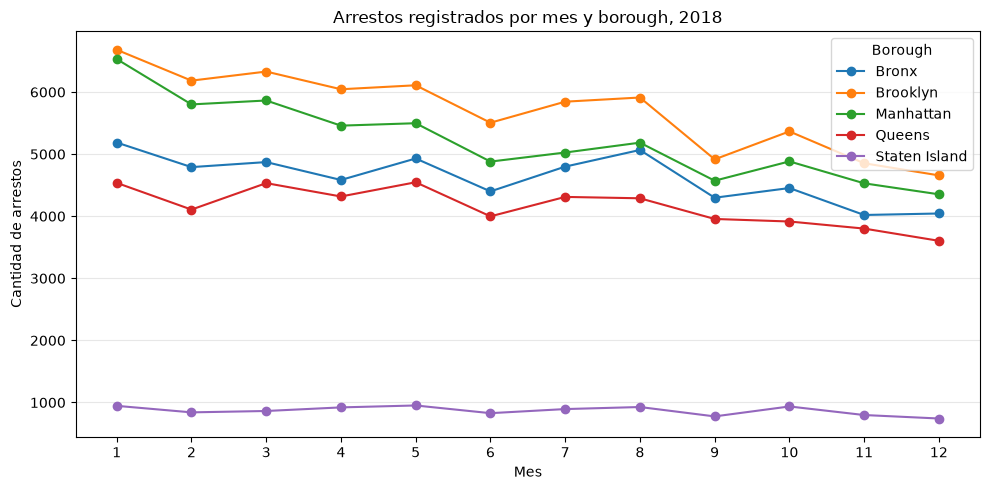

In [27]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window
import matplotlib.pyplot as plt

# Conteo mensual por borough
arrestos_mes = (
    base_analitica
    .filter(
        (F.year("fecha") == 2018) &
        F.col("arrest_boro_nombre").isin(
            "Bronx", "Brooklyn", "Manhattan", "Queens", "Staten Island"
        )
    )
    .groupBy("arrest_boro_nombre", "mes")
    .agg(F.countDistinct("arrest_key").alias("arrestos"))
)

# Porcentaje del total anual de cada borough que corresponde a cada mes
ventana_borough = Window.partitionBy("arrest_boro_nombre")

arrestos_mes = (
    arrestos_mes
    .withColumn(
        "porcentaje_anual_borough",
        F.round(
            F.col("arrestos") / F.sum("arrestos").over(ventana_borough) * 100,
            2
        )
    )
    .orderBy("arrest_boro_nombre", "mes")
)

arrestos_mes.show(60, truncate=False)

# Gráfica de conteos mensuales
datos_grafica = arrestos_mes.toPandas()
tabla_grafica = datos_grafica.pivot(
    index="mes",
    columns="arrest_boro_nombre",
    values="arrestos"
).sort_index()

tabla_grafica.plot(marker="o", figsize=(10, 5))
plt.title("Arrestos registrados por mes y borough, 2018")
plt.xlabel("Mes")
plt.ylabel("Cantidad de arrestos")
plt.xticks(range(1, 13))
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Borough")
plt.tight_layout()
plt.show()

/opt/cluster/spark/python/lib/pyspark.zip/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/cluster/spark/python/lib/pyspark.zip/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


Datos utilizados en la gráfica:
 mes arrest_boro_nombre  arrestos  poblacion  tasa_mensual_100k
   1              Bronx      5187    1432000              362.2
   1           Brooklyn      6681    2583000              258.7
   1          Manhattan      6531    1629000              400.9
   1             Queens      4537    2279000              199.1
   1      Staten Island       946     476000              198.7
   2              Bronx      4791    1432000              334.6
   2           Brooklyn      6184    2583000              239.4
   2          Manhattan      5801    1629000              356.1
   2             Queens      4107    2279000              180.2
   2      Staten Island       841     476000              176.7
   3              Bronx      4872    1432000              340.2
   3           Brooklyn      6330    2583000              245.1
   3          Manhattan      5864    1629000              360.0
   3             Queens      4533    2279000              198.9
   3    

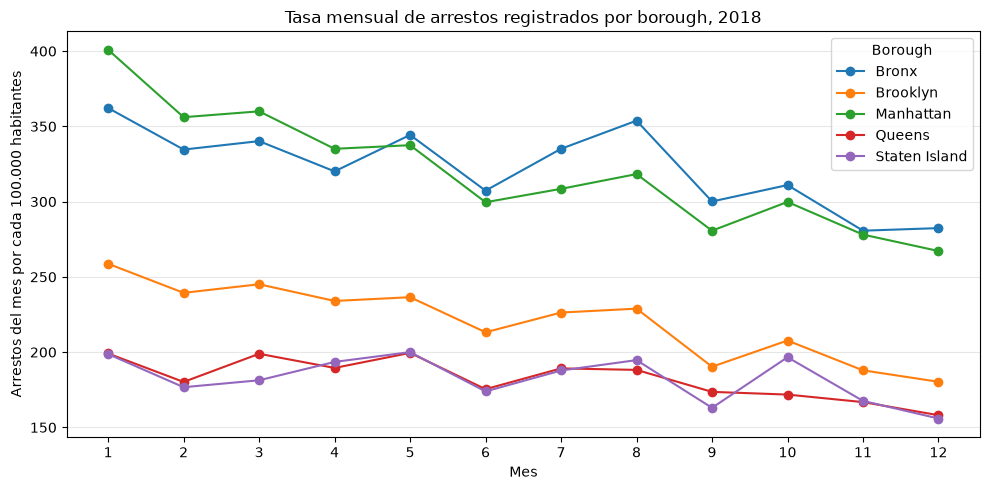

In [30]:
# Población de 2018 por borough
poblacion_2018 = spark.createDataFrame(
    [
        ("Bronx", 1432000),
        ("Brooklyn", 2583000),
        ("Manhattan", 1629000),
        ("Queens", 2279000),
        ("Staten Island", 476000),
    ],
    ["arrest_boro_nombre", "poblacion"]
)

# Tasa mensual por cada 100.000 habitantes
tasas_mes = (
    arrestos_mes
    .join(poblacion_2018, on="arrest_boro_nombre", how="inner")
    .withColumn(
        "tasa_mensual_100k",
        F.round(F.col("arrestos") / F.col("poblacion") * 100000, 1)
    )
    .orderBy("mes", "arrest_boro_nombre")
)

# Datos para cada punto de la gráfica
datos_grafica = tasas_mes.select(
    "mes",
    "arrest_boro_nombre",
    "arrestos",
    "poblacion",
    "tasa_mensual_100k"
).toPandas()

print("Datos utilizados en la gráfica:")
print(datos_grafica.to_string(index=False), "\n\n\n")


# Preparar las tasas para la gráfica
tabla_grafica = datos_grafica.pivot(
    index="mes",
    columns="arrest_boro_nombre",
    values="tasa_mensual_100k"
).sort_index()

tabla_grafica.plot(marker="o", figsize=(10, 5))
plt.title("Tasa mensual de arrestos registrados por borough, 2018")
plt.xlabel("Mes")
plt.ylabel("Arrestos del mes por cada 100.000 habitantes")
plt.xticks(range(1, 13))
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Borough")
plt.tight_layout()
plt.show()

## CONCLUSIONES P1
# P1: ¿Cómo se distribuyen los arrestos por territorio y período durante el año disponible?

Analizando la gráfica se puede observar que las tasas mensuales son menores en diciembre que en enero en los cinco boroughs, aunque presentan fluctuaciones y no disminuyen de forma continua. Manhattan registra la tasa más alta de toda la serie en enero (400,9 arrestos por cada 100.000 habitantes). El Bronx comienza en 362,2 y, desde mayo hasta diciembre, presenta tasas superiores a Manhattan. Brooklyn ocupa una posición intermedia. Queens y Staten Island tienen las tasas más bajas y cercanas entre sí y sus valores se cruzan en varios meses.  

# P2. Composición de las categorías de arresto

**Pregunta:** ¿Cómo cambia la composición de las categorías de arresto entre territorios y períodos?

En P1 analizamos el volumen y la tasa de arrestos. Ahora estudiaremos qué categorías componen esos arrestos y cómo varían entre los cinco boroughs y los cuatro trimestres de 2018.

Primero analizaremos la categoría legal (`law_cat_cd_analisis`) y después los tipos de delito (`ofns_desc_analisis`). Para cada borough y trimestre calcularemos los conteos y el porcentaje que representa cada categoría sobre el total de arrestos de ese grupo. Se conservarán las categorías “No especificado” y, para `ofns_desc`, “Otras”, de modo que los porcentajes incluyan todos los registros.

La comparación será descriptiva: buscaremos diferencias de composición entre boroughs y trimestres. Al final evaluaremos si el patrón cambia al considerar únicamente arrestos de NYPD (`es_nypd = 1`).

Antes de calcular composiciones, verificamos que la base analítica forme los 20 grupos esperados: 5 boroughs × 4 trimestres. Contaremos arrestos únicos por arrest_key. Estos conteos serán los denominadores para calcular los porcentajes de cada categoría dentro de cada borough–trimestre.

In [32]:
conteo_boro_trimestre = (
    base_analitica
    .groupBy("arrest_boro_nombre", "trimestre")
    .agg(F.countDistinct("arrest_key").alias("arrestos"))
    .orderBy("arrest_boro_nombre", "trimestre")
)

conteo_boro_trimestre.show(25, truncate=False)

filas_base = base_analitica.count()
grupos_observados = conteo_boro_trimestre.count()
arrestos_en_grupos = conteo_boro_trimestre.agg(
    F.sum("arrestos").alias("total")
).first()["total"]

print("Filas en base analítica:", filas_base)
print("Grupos borough-trimestre observados:", grupos_observados)
print("Grupos esperados:", 5 * 4)
print("Arrestos sumados en los grupos:", arrestos_en_grupos)

+------------------+---------+--------+
|arrest_boro_nombre|trimestre|arrestos|
+------------------+---------+--------+
|Bronx             |1        |14850   |
|Bronx             |2        |13914   |
|Bronx             |3        |14164   |
|Bronx             |4        |12518   |
|Brooklyn          |1        |19195   |
|Brooklyn          |2        |17660   |
|Brooklyn          |3        |16673   |
|Brooklyn          |4        |14877   |
|Manhattan         |1        |18196   |
|Manhattan         |2        |15837   |
|Manhattan         |3        |14783   |
|Manhattan         |4        |13766   |
|Queens            |1        |13177   |
|Queens            |2        |12863   |
|Queens            |3        |12556   |
|Queens            |4        |11320   |
|Staten Island     |1        |2650    |
|Staten Island     |2        |2701    |
|Staten Island     |3        |2597    |
|Staten Island     |4        |2476    |
+------------------+---------+--------+

Filas en base analítica: 246773
Grupos 

## Composicion por categoría legal - law_cat_cd_analisis

Para comparar la composición legal, calculamos el número de arrestos y el porcentaje de cada categoría (F, M, V, I y “No especificado”) dentro de cada borough–trimestre. El denominador incluye todos los arrestos del grupo, incluidos los que no tienen categoría legal especificada, por eso los porcentajes de cada grupo deben sumar aproximadamente 100 %.

In [33]:
from pyspark.sql.window import Window

conteo_legal = (
    base_analitica
    .groupBy(
        "arrest_boro_nombre",
        "trimestre",
        "law_cat_cd_analisis"
    )
    .agg(F.countDistinct("arrest_key").alias("arrestos"))
)

ventana_grupo = Window.partitionBy("arrest_boro_nombre", "trimestre")

composicion_legal = (
    conteo_legal
    .withColumn(
        "total_grupo",
        F.sum("arrestos").over(ventana_grupo)
    )
    .withColumn(
        "porcentaje",
        F.round(F.col("arrestos") / F.col("total_grupo") * 100, 2)
    )
    .orderBy(
        "arrest_boro_nombre",
        "trimestre",
        "law_cat_cd_analisis"
    )
)

composicion_legal.show(100, truncate=False)

[Stage 465:============================>                            (1 + 1) / 2]

+------------------+---------+-------------------+--------+-----------+----------+
|arrest_boro_nombre|trimestre|law_cat_cd_analisis|arrestos|total_grupo|porcentaje|
+------------------+---------+-------------------+--------+-----------+----------+
|Bronx             |1        |F                  |4342    |14850      |29.24     |
|Bronx             |1        |I                  |14      |14850      |0.09      |
|Bronx             |1        |M                  |10365   |14850      |69.8      |
|Bronx             |1        |No especificado    |104     |14850      |0.7       |
|Bronx             |1        |V                  |25      |14850      |0.17      |
|Bronx             |2        |F                  |4343    |13914      |31.21     |
|Bronx             |2        |I                  |6       |13914      |0.04      |
|Bronx             |2        |M                  |9389    |13914      |67.48     |
|Bronx             |2        |No especificado    |108     |13914      |0.78      |
|Bro

 M es la categoría legal más frecuente en los 20 grupos borough–trimestre. Su participación va de 54,28 % en Brooklyn durante el trimestre 4 a 69,80 % en Bronx durante el trimestre 1. F es la segunda categoría más frecuente. En Brooklyn su participación aumenta de 35,64 % en el trimestre 1 a 43,16 % en el trimestre 4, mientras que la participación de M baja de 61,45 % a 54,28 %. V e I representan proporciones pequeñas. “No especificado” se mantiene por debajo de 1,4 % en todos los grupos; su máximo es 1,39 % en Manhattan, trimestre 3. Estos porcentajes describen composición dentro de cada grupo.
 
La categoría M significa Misdemeanor, lo cual es un delito de gravedad intermedia. Incluye infracciones como hurto menor, asalto simple o posesión menor de sustancias controladas, castigados generalmente con hasta un año de cárcel local o libertad condicional. F por otro lado significa Felony y es la categoría más severa. Incluye crímenes mayores como homicidio, robo agravado, asalto grave o tráfico de drogas a gran escala, los cuales conllevan penas de prisión estatal superiores a un año.

De estos datos se puede inferir que la mayoría de arrestos que se dieron en NYC en 2018 fueron por delitos **Felony** y **Misdemeanor**. 
 

/opt/cluster/spark/python/lib/pyspark.zip/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/cluster/spark/python/lib/pyspark.zip/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


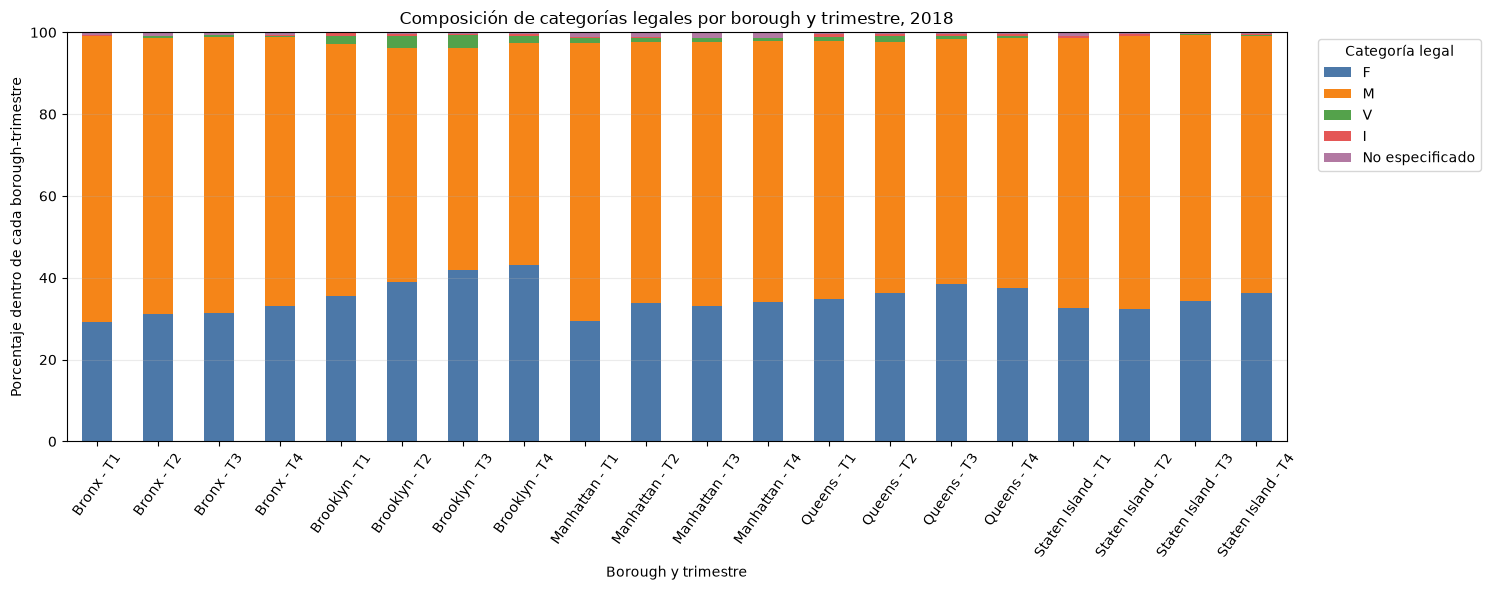

In [36]:
datos_grafica_legal = composicion_legal.select(
    "arrest_boro_nombre",
    "trimestre",
    "law_cat_cd_analisis",
    "arrestos",
    "total_grupo"
).toPandas()

# Usamos porcentajes sin redondear para que cada barra sume 100 %
datos_grafica_legal["porcentaje_grafica"] = (
    datos_grafica_legal["arrestos"]
    / datos_grafica_legal["total_grupo"]
    * 100
)

orden_boroughs = [
    "Bronx",
    "Brooklyn",
    "Manhattan",
    "Queens",
    "Staten Island"
]

orden_grupos = [
    f"{boro} - T{trimestre}"
    for boro in orden_boroughs
    for trimestre in range(1, 5)
]

datos_grafica_legal["grupo"] = (
    datos_grafica_legal["arrest_boro_nombre"]
    + " - T"
    + datos_grafica_legal["trimestre"].astype(str)
)

tabla_grafica_legal = datos_grafica_legal.pivot(
    index="grupo",
    columns="law_cat_cd_analisis",
    values="porcentaje_grafica"
)

orden_categorias = ["F", "M", "V", "I", "No especificado"]
categorias_presentes = [
    categoria
    for categoria in orden_categorias
    if categoria in tabla_grafica_legal.columns
]

tabla_grafica_legal = (
    tabla_grafica_legal
    .reindex(index=orden_grupos, columns=categorias_presentes)
    .fillna(0)
)

colores = {
    "F": "#4C78A8",
    "M": "#F58518",
    "V": "#54A24B",
    "I": "#E45756",
    "No especificado": "#B279A2"
}

ax = tabla_grafica_legal.plot(
    kind="bar",
    stacked=True,
    figsize=(15, 6),
    color=[colores[categoria] for categoria in tabla_grafica_legal.columns]
)

ax.set_ylim(0, 100)
ax.set_title("Composición de categorías legales por borough y trimestre, 2018")
ax.set_xlabel("Borough y trimestre")
ax.set_ylabel("Porcentaje dentro de cada borough-trimestre")
ax.tick_params(axis="x", labelrotation=55)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Categoría legal", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

Como se puede observar en la imagen y en los datos obtenidos anteriormente, se puede observar que trimestralmente las dos categorías legales de delito que predominan son Felony y Misdemeanor siendo Felony el que más arrestos presenta en todos los quarters. 

## Composicion por tipo de delito - ofns_desc_analisis


Aquí calcularemos cuántos arrestos y qué porcentaje corresponden a cada categoría de ofns_desc_analisis dentro de cada borough–trimestre. El denominador incluye todos los arrestos del grupo, también “Otras” y “No especificado”. Usamos la agrupación global Top 10 + “Otras” + “No especificado” ya definida para poder comparar los mismos tipos de categorías entre grupos. Después revisaremos la cobertura del Top 10 en cada grupo.

In [37]:
conteo_delitos = (
    base_analitica
    .groupBy(
        "arrest_boro_nombre",
        "trimestre",
        "ofns_desc_analisis"
    )
    .agg(F.countDistinct("arrest_key").alias("arrestos"))
)

ventana_grupo = Window.partitionBy("arrest_boro_nombre", "trimestre")

composicion_delitos = (
    conteo_delitos
    .withColumn(
        "total_grupo",
        F.sum("arrestos").over(ventana_grupo)
    )
    .withColumn(
        "porcentaje",
        F.round(F.col("arrestos") / F.col("total_grupo") * 100, 2)
    )
    .orderBy(
        "arrest_boro_nombre",
        "trimestre",
        F.desc("arrestos")
    )
)

composicion_delitos.show(240, truncate=False)

+------------------+---------+------------------------------------+--------+-----------+----------+
|arrest_boro_nombre|trimestre|ofns_desc_analisis                  |arrestos|total_grupo|porcentaje|
+------------------+---------+------------------------------------+--------+-----------+----------+
|Bronx             |1        |Otras                               |3594    |14850      |24.2      |
|Bronx             |1        |DANGEROUS DRUGS                     |2757    |14850      |18.57     |
|Bronx             |1        |ASSAULT 3 & RELATED OFFENSES        |2490    |14850      |16.77     |
|Bronx             |1        |VEHICLE AND TRAFFIC LAWS            |1510    |14850      |10.17     |
|Bronx             |1        |FELONY ASSAULT                      |958     |14850      |6.45      |
|Bronx             |1        |PETIT LARCENY                       |956     |14850      |6.44      |
|Bronx             |1        |DANGEROUS WEAPONS                   |641     |14850      |4.32      |


In [40]:
ventana_top3 = (
    Window
    .partitionBy("arrest_boro_nombre", "trimestre")
    .orderBy(
        F.desc("arrestos"),
        F.asc("ofns_desc_analisis")
    )
)

top3_categorias_delito = (
    composicion_delitos
    .withColumn("rango", F.row_number().over(ventana_top3))
    .filter(F.col("rango") <= 3)
    .select(
        "arrest_boro_nombre",
        "trimestre",
        "rango",
        "ofns_desc_analisis",
        "arrestos",
        "total_grupo",
        "porcentaje"
    )
    .orderBy("arrest_boro_nombre", "trimestre", "rango")
)

top3_categorias_delito.show(60, truncate=False)

+------------------+---------+-----+----------------------------+--------+-----------+----------+
|arrest_boro_nombre|trimestre|rango|ofns_desc_analisis          |arrestos|total_grupo|porcentaje|
+------------------+---------+-----+----------------------------+--------+-----------+----------+
|Bronx             |1        |1    |Otras                       |3594    |14850      |24.2      |
|Bronx             |1        |2    |DANGEROUS DRUGS             |2757    |14850      |18.57     |
|Bronx             |1        |3    |ASSAULT 3 & RELATED OFFENSES|2490    |14850      |16.77     |
|Bronx             |2        |1    |Otras                       |3451    |13914      |24.8      |
|Bronx             |2        |2    |ASSAULT 3 & RELATED OFFENSES|2664    |13914      |19.15     |
|Bronx             |2        |3    |DANGEROUS DRUGS             |2227    |13914      |16.01     |
|Bronx             |3        |1    |Otras                       |3730    |14164      |26.33     |
|Bronx             |

“Otras” es la categoría analítica más frecuente en todos los boroughs y trimestres: representa entre 23,73 % (Staten Island, T2) y 31,57 % (Manhattan, T1). Como agrupa delitos fuera del Top 10 global, no debe interpretarse como un delito individual.

Entre las categorías de delito identificadas, ASSAULT 3 & RELATED OFFENSES y DANGEROUS DRUGS aparecen repetidamente entre las más frecuentes. En Bronx, DANGEROUS DRUGS ocupa el segundo lugar en T1 y ASSAULT 3 & RELATED OFFENSES lo ocupa de T2 a T4. En Brooklyn, DANGEROUS DRUGS está en segundo lugar en T1 y T2, mientras que ASSAULT 3 & RELATED OFFENSES pasa al segundo lugar en T3 y T4. En Manhattan, PETIT LARCENY ocupa el segundo lugar de T2 a T4; en Queens, ASSAULT 3 & RELATED OFFENSES está en segundo lugar en los cuatro trimestres. En Staten Island, DANGEROUS DRUGS queda en segundo lugar y ASSAULT 3 & RELATED OFFENSES en tercero durante todo el año.

Los porcentajes corresponden a la participación sobre todos los arrestos del borough–trimestre. Estos resultados describen la composición de los registros

 El Top 10 se definió globalmente para mantener las mismas categorías al comparar boroughs y trimestres. Ahora revisamos qué porcentaje cubre dentro de cada grupo. Calculamos esa cobertura excluyendo “Otras” y “No especificado” del conteo Top 10, pero usamos como denominador todos los arrestos del grupo.

In [41]:
cobertura_top10_por_grupo = (
    composicion_delitos
    .groupBy("arrest_boro_nombre", "trimestre")
    .agg(
        F.sum(
            F.when(
                ~F.col("ofns_desc_analisis").isin(
                    "Otras", "No especificado"
                ),
                F.col("arrestos")
            ).otherwise(0)
        ).alias("arrestos_top10"),
        F.sum(
            F.when(
                F.col("ofns_desc_analisis") == "Otras",
                F.col("arrestos")
            ).otherwise(0)
        ).alias("arrestos_otras"),
        F.sum(
            F.when(
                F.col("ofns_desc_analisis") == "No especificado",
                F.col("arrestos")
            ).otherwise(0)
        ).alias("arrestos_no_especificado"),
        F.sum("arrestos").alias("total_grupo")
    )
    .withColumn(
        "porcentaje_top10",
        F.round(F.col("arrestos_top10") / F.col("total_grupo") * 100, 2)
    )
    .withColumn(
        "porcentaje_otras",
        F.round(F.col("arrestos_otras") / F.col("total_grupo") * 100, 2)
    )
    .withColumn(
        "porcentaje_no_especificado",
        F.round(
            F.col("arrestos_no_especificado") / F.col("total_grupo") * 100,
            2
        )
    )
    .withColumn(
        "cumple_70_por_ciento",
        F.col("porcentaje_top10") >= 70
    )
    .orderBy("arrest_boro_nombre", "trimestre")
)

cobertura_top10_por_grupo.show(20, truncate=False)

+------------------+---------+--------------+--------------+------------------------+-----------+----------------+----------------+--------------------------+--------------------+
|arrest_boro_nombre|trimestre|arrestos_top10|arrestos_otras|arrestos_no_especificado|total_grupo|porcentaje_top10|porcentaje_otras|porcentaje_no_especificado|cumple_70_por_ciento|
+------------------+---------+--------------+--------------+------------------------+-----------+----------------+----------------+--------------------------+--------------------+
|Bronx             |1        |11191         |3594          |65                      |14850      |75.36           |24.2            |0.44                      |true                |
|Bronx             |2        |10415         |3451          |48                      |13914      |74.85           |24.8            |0.34                      |true                |
|Bronx             |3        |10386         |3730          |48                      |14164      |73.

El Top 10 global cubre al menos 70 % de los arrestos en 16 de los 20 grupos borough–trimestre. La cobertura menor se observa en Manhattan, T1 (67,95 %); también queda bajo el umbral en Brooklyn, T3, y Queens, T1 y T3. En esos grupos, “Otras” representa entre 29,90 % y 31,57 %. “No especificado” es bajo en todos los grupos (0,12 %–0,63 %). Se conserva la agrupación Top 10 + “Otras” + “No especificado” para mantener categorías comparables.

/opt/cluster/spark/python/lib/pyspark.zip/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/cluster/spark/python/lib/pyspark.zip/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


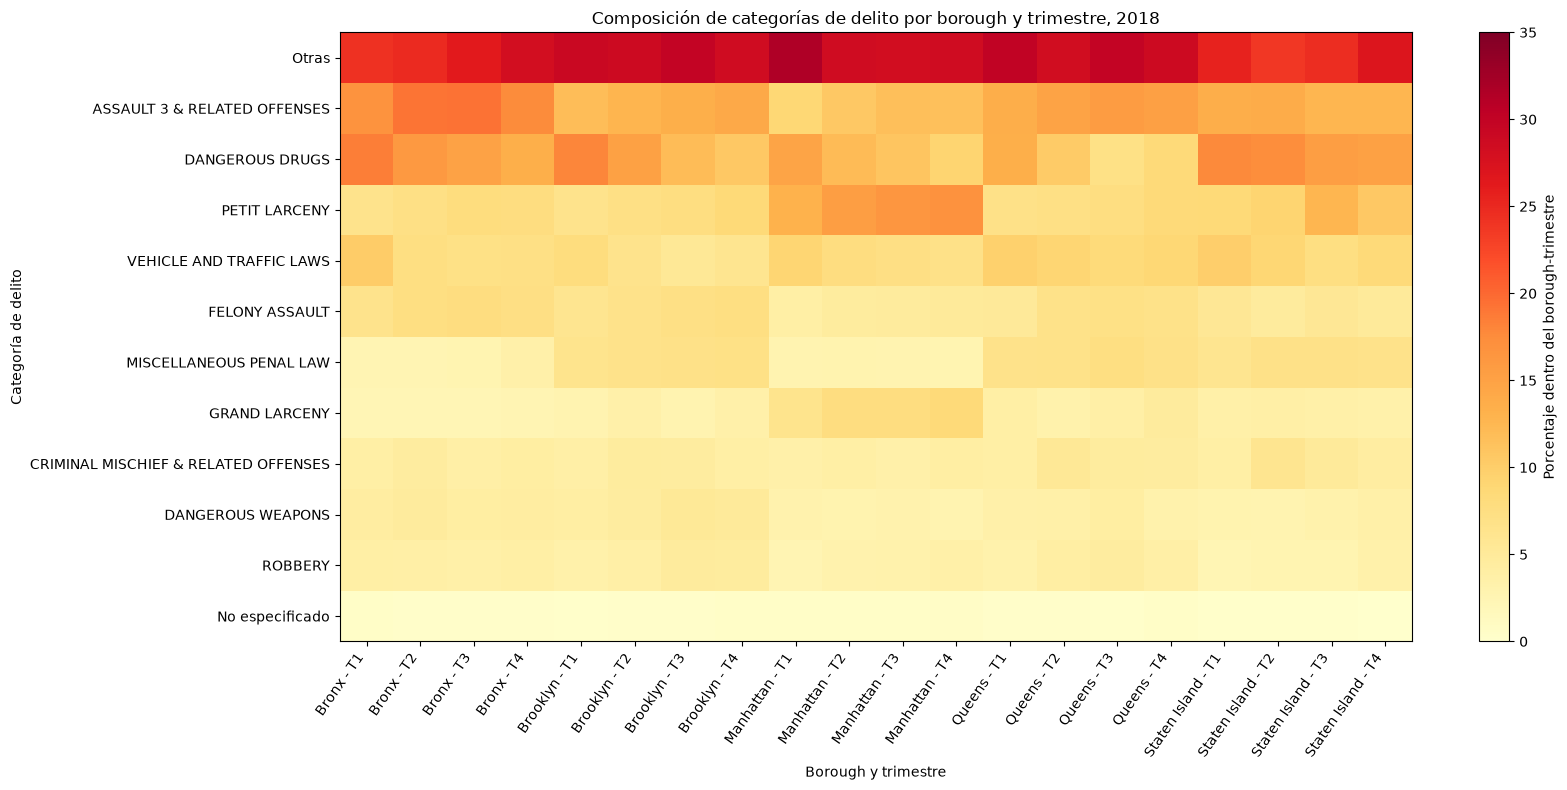

In [43]:
datos_heatmap_delitos = composicion_delitos.select(
    "arrest_boro_nombre",
    "trimestre",
    "ofns_desc_analisis",
    "arrestos",
    "porcentaje"
).toPandas()

# Ordenar columnas por borough y trimestre
orden_boroughs = [
    "Bronx",
    "Brooklyn",
    "Manhattan",
    "Queens",
    "Staten Island"
]

orden_grupos = [
    f"{boro} - T{trimestre}"
    for boro in orden_boroughs
    for trimestre in range(1, 5)
]

datos_heatmap_delitos["grupo"] = (
    datos_heatmap_delitos["arrest_boro_nombre"]
    + " - T"
    + datos_heatmap_delitos["trimestre"].astype(str)
)

# Ordenar las filas de categorías por frecuencia total
orden_categorias = (
    datos_heatmap_delitos
    .groupby("ofns_desc_analisis")["arrestos"]
    .sum()
    .sort_values(ascending=False)
    .index
    .tolist()
)

tabla_heatmap_delitos = datos_heatmap_delitos.pivot(
    index="ofns_desc_analisis",
    columns="grupo",
    values="porcentaje"
).reindex(
    index=orden_categorias,
    columns=orden_grupos
).fillna(0)

fig, ax = plt.subplots(figsize=(17, 8))

imagen = ax.imshow(
    tabla_heatmap_delitos.values,
    aspect="auto",
    cmap="YlOrRd",
    vmin=0,
    vmax=35
)

ax.set_xticks(range(len(orden_grupos)))
ax.set_xticklabels(orden_grupos, rotation=55, ha="right")

ax.set_yticks(range(len(orden_categorias)))
ax.set_yticklabels(orden_categorias)

ax.set_title("Composición de categorías de delito por borough y trimestre, 2018")
ax.set_xlabel("Borough y trimestre")
ax.set_ylabel("Categoría de delito")

barra_color = fig.colorbar(imagen, ax=ax)
barra_color.set_label("Porcentaje dentro del borough-trimestre")

plt.tight_layout()
plt.show()

La gráfica sintetiza los porcentajes de la tabla por borough y trimestre. Se observa que “Otras” es la categoría analítica más grande en todos los grupos, mientras que las categorías individuales que siguen varían según el borough y el trimestre. Los colores representan porcentajes dentro de cada grupo, no cantidades de arrestos; los valores específicos se detallan en la tabla del Top 3.

### Sensibilidad de P2 a la jurisdicción: categoría legal

**Objetivo.** Evaluar si incluir los arrestos de jurisdicciones no NYPD cambia la composición legal observada en cada borough y trimestre.

Para cada combinación de borough–trimestre y categoría legal, compararemos dos porcentajes:

1. **Todos los arrestos:** registros NYPD y no NYPD; el denominador es el total de arrestos del grupo.
2. **Solo NYPD:** registros con `es_nypd = 1`; el denominador es el total de arrestos NYPD del mismo grupo.

Calcularemos la diferencia absoluta entre ambos porcentajes en puntos porcentuales (Δpp). Esto es una prueba de sensibilidad: no elimina registros de la base principal. Revisaremos el cambio máximo y cuántas combinaciones alcanzan o superan 1 pp.

In [49]:
columnas_sensibilidad = [
    "arrest_boro_nombre",
    "trimestre",
    "law_cat_cd_analisis"
]

def composicion_legal_por_escenario(df):
    conteos = (
        df.groupBy(*columnas_sensibilidad)
          .agg(F.countDistinct("arrest_key").alias("arrestos"))
    )

    denominadores = (
        df.groupBy("arrest_boro_nombre", "trimestre")
          .agg(F.countDistinct("arrest_key").alias("total_grupo"))
    )

    return (
        conteos
        .join(
            denominadores,
            on=["arrest_boro_nombre", "trimestre"],
            how="inner"
        )
        .withColumn(
            "porcentaje",
            F.col("arrestos") / F.col("total_grupo") * 100
        )
    )

# Escenario 1: todos los arrestos
composicion_todos = (
    composicion_legal_por_escenario(base_analitica)
    .select(
        *columnas_sensibilidad,
        F.col("arrestos").alias("arrestos_todos"),
        F.col("porcentaje").alias("pct_todos")
    )
)

# Escenario 2: solo registros NYPD
composicion_nypd = (
    composicion_legal_por_escenario(
        base_analitica.filter(F.col("es_nypd") == 1)
    )
    .select(
        *columnas_sensibilidad,
        F.col("arrestos").alias("arrestos_nypd"),
        F.col("porcentaje").alias("pct_nypd")
    )
)

sensibilidad_legal = (
    composicion_todos
    .join(
        composicion_nypd,
        on=columnas_sensibilidad,
        how="full_outer"
    )
    .withColumn(
        "arrestos_todos",
        F.coalesce(F.col("arrestos_todos"), F.lit(0))
    )
    .withColumn(
        "arrestos_nypd",
        F.coalesce(F.col("arrestos_nypd"), F.lit(0))
    )
    .withColumn(
        "pct_todos",
        F.coalesce(F.col("pct_todos"), F.lit(0))
    )
    .withColumn(
        "pct_nypd",
        F.coalesce(F.col("pct_nypd"), F.lit(0))
    )
    .withColumn(
        "delta_pp",
        F.round(F.abs(F.col("pct_todos") - F.col("pct_nypd")), 2)
    )
    .orderBy(F.desc("delta_pp"))
)

sensibilidad_legal.select(
    "arrest_boro_nombre",
    "trimestre",
    "law_cat_cd_analisis",
    "arrestos_todos",
    F.round("pct_todos", 2).alias("pct_todos"),
    "arrestos_nypd",
    F.round("pct_nypd", 2).alias("pct_nypd"),
    "delta_pp"
).show(100, truncate=False)

print("Máximo Δpp:", sensibilidad_legal.agg(F.max("delta_pp")).first()[0])
print(
    "Combinaciones con Δpp >= 1:",
    sensibilidad_legal.filter(F.col("delta_pp") >= 1).count()
)

+------------------+---------+-------------------+--------------+---------+-------------+--------+--------+
|arrest_boro_nombre|trimestre|law_cat_cd_analisis|arrestos_todos|pct_todos|arrestos_nypd|pct_nypd|delta_pp|
+------------------+---------+-------------------+--------------+---------+-------------+--------+--------+
|Queens            |4        |M                  |6919          |61.12    |6187         |59.18   |1.94    |
|Queens            |4        |F                  |4232          |37.39    |4107         |39.29   |1.9     |
|Queens            |3        |M                  |7510          |59.81    |6764         |57.93   |1.89    |
|Queens            |3        |F                  |4835          |38.51    |4705         |40.29   |1.79    |
|Queens            |2        |M                  |7905          |61.46    |7252         |60.15   |1.31    |
|Queens            |2        |F                  |4657          |36.2     |4514         |37.44   |1.23    |
|Queens            |1       

Máximo Δpp: 1.94
Combinaciones con Δpp >= 1: 6


 El máximo cambio entre todos los arrestos y solo los registros NYPD es 1,94 pp. Seis combinaciones categoría–trimestre superan el umbral operativo de 1 pp; todas corresponden a F o M en Queens durante T2, T3 y T4. En esas combinaciones, al considerar solo NYPD, disminuye la participación de M y aumenta la de F. En los demás grupos, las diferencias son menores a 1 pp. Por este criterio, la composición legal presenta un cambio localizado en Queens; por eso mantenemos todos los arrestos en el análisis principal y reportamos la comparación con NYPD como sensibilidad.

Repetimos la comparación anterior usando ofns_desc_analisis. Para cada categoría y borough–trimestre comparamos su porcentaje entre todos los arrestos y solo los registros NYPD. Recalculamos el denominador dentro de cada escenario y conservamos “Otras” y “No especificado”. Mostraremos las combinaciones cuyo cambio absoluto alcanza 1 pp o más; la base principal sigue incluyendo todos los arrestos.

In [50]:
columnas_sensibilidad_delitos = [
    "arrest_boro_nombre",
    "trimestre",
    "ofns_desc_analisis"
]

def composicion_delitos_por_escenario(df):
    conteos = (
        df.groupBy(*columnas_sensibilidad_delitos)
          .agg(F.countDistinct("arrest_key").alias("arrestos"))
    )

    denominadores = (
        df.groupBy("arrest_boro_nombre", "trimestre")
          .agg(F.countDistinct("arrest_key").alias("total_grupo"))
    )

    return (
        conteos
        .join(
            denominadores,
            on=["arrest_boro_nombre", "trimestre"],
            how="inner"
        )
        .withColumn(
            "porcentaje",
            F.col("arrestos") / F.col("total_grupo") * 100
        )
    )

delitos_todos = (
    composicion_delitos_por_escenario(base_analitica)
    .select(
        *columnas_sensibilidad_delitos,
        F.col("arrestos").alias("arrestos_todos"),
        F.col("porcentaje").alias("pct_todos")
    )
)

delitos_nypd = (
    composicion_delitos_por_escenario(
        base_analitica.filter(F.col("es_nypd") == 1)
    )
    .select(
        *columnas_sensibilidad_delitos,
        F.col("arrestos").alias("arrestos_nypd"),
        F.col("porcentaje").alias("pct_nypd")
    )
)

sensibilidad_delitos = (
    delitos_todos
    .join(
        delitos_nypd,
        on=columnas_sensibilidad_delitos,
        how="full_outer"
    )
    .withColumn(
        "arrestos_todos",
        F.coalesce(F.col("arrestos_todos"), F.lit(0))
    )
    .withColumn(
        "arrestos_nypd",
        F.coalesce(F.col("arrestos_nypd"), F.lit(0))
    )
    .withColumn(
        "pct_todos",
        F.coalesce(F.col("pct_todos"), F.lit(0))
    )
    .withColumn(
        "pct_nypd",
        F.coalesce(F.col("pct_nypd"), F.lit(0))
    )
    .withColumn(
        "delta_pp",
        F.round(F.abs(F.col("pct_todos") - F.col("pct_nypd")), 2)
    )
)

print(
    "Máximo Δpp:",
    sensibilidad_delitos.agg(F.max("delta_pp")).first()[0]
)

print(
    "Combinaciones con Δpp >= 1:",
    sensibilidad_delitos.filter(F.col("delta_pp") >= 1).count()
)

sensibilidad_delitos \
    .filter(F.col("delta_pp") >= 1) \
    .orderBy(F.desc("delta_pp")) \
    .show(100, truncate=False)

Máximo Δpp: 3.13


Combinaciones con Δpp >= 1: 7


+------------------+---------+----------------------------+--------------+------------------+-------------+------------------+--------+
|arrest_boro_nombre|trimestre|ofns_desc_analisis          |arrestos_todos|pct_todos         |arrestos_nypd|pct_nypd          |delta_pp|
+------------------+---------+----------------------------+--------------+------------------+-------------+------------------+--------+
|Queens            |4        |VEHICLE AND TRAFFIC LAWS    |991           |8.754416961130742 |588          |5.624641285632294 |3.13    |
|Queens            |3        |VEHICLE AND TRAFFIC LAWS    |1037          |8.258999681427207 |657          |5.626445148582683 |2.63    |
|Queens            |2        |VEHICLE AND TRAFFIC LAWS    |1169          |9.088082095934075 |805          |6.676619391225016 |2.41    |
|Queens            |1        |VEHICLE AND TRAFFIC LAWS    |1273          |9.660772558245426 |963          |7.708316657328104 |1.95    |
|Staten Island     |3        |Otras             

El mayor cambio al considerar solo los registros NYPD es 3,13 pp: la participación de VEHICLE AND TRAFFIC LAWS en Queens–T4 pasa de 8,75 % con todos los arrestos a 5,62 % con solo NYPD. En Queens, esta categoría supera el umbral de 1 pp en los cuatro trimestres. También lo superan ASSAULT 3 & RELATED OFFENSES en Queens–T3 y T4, y “Otras” en Staten Island–T3. En total, 7 combinaciones categoría–borough–trimestre tienen Δpp ≥ 1.

Este cambio está concentrado principalmente en VEHICLE AND TRAFFIC LAWS de Queens; no indica que todas las categorías cambien de manera importante. Se conserva la base completa en el análisis principal y se informa esta sensibilidad.

### Test 1: asociación entre borough y categoría legal

**Relación con P2.** P2 pregunta cómo cambia la composición de las categorías de arresto entre territorios y períodos. En este primer test aislamos la dimensión territorial para la categoría legal: comparamos los conteos de F, M, V, I y “No especificado” entre los cinco boroughs, agrupando los cuatro trimestres de 2018. La tabla de contingencia borough × categoría legal nos permite evaluar si las diferencias de composición observadas son mayores de lo que cabría esperar si ambas variables fueran independientes.

- **H₀:** borough y categoría legal son independientes; la distribución de categorías legales es igual entre los boroughs.
- **H₁:** borough y categoría legal están asociados; la distribución difiere en al menos un borough.

Aplicaremos chi-cuadrado de independencia, con (alpha=0,05), a los conteos y no a los porcentajes e incluiremos “No especificado”. Calcularemos también V de Cramér para estimar la magnitud de la asociación: el *p*-valor indica si hay evidencia de diferencias, mientras que V de Cramér ayuda a valorar si su tamaño es pequeño o grande.

Antes de interpretar el resultado verificaremos los conteos esperados. Este test resume el patrón anual: no evalúa los cambios entre trimestres ni la interacción borough–trimestre.

In [53]:
%pip install scipy

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 23.7 MB/s eta 0:00:0000:0100:01
Note: you may need to restart the kernel to use updated packages.


In [54]:
import numpy as np
from scipy.stats import chi2_contingency

# Conteos observados: borough × categoría legal
tabla_observada = (
    base_analitica
    .groupBy("arrest_boro_nombre", "law_cat_cd_analisis")
    .agg(F.countDistinct("arrest_key").alias("arrestos"))
    .toPandas()
    .pivot(
        index="arrest_boro_nombre",
        columns="law_cat_cd_analisis",
        values="arrestos"
    )
    .fillna(0)
)

observados = tabla_observada.to_numpy()

# Test chi-cuadrado y frecuencias esperadas bajo H₀
chi2, p_valor, grados_libertad, esperados = chi2_contingency(
    observados,
    correction=False
)

n = observados.sum()
v_cramer = np.sqrt(
    chi2 /
    (n * min(tabla_observada.shape[0] - 1,
             tabla_observada.shape[1] - 1))
)

alpha = 0.05
decision = "Rechazar H₀" if p_valor < alpha else "No rechazar H₀"

print("Tabla observada:")
print(tabla_observada.to_string())

print(f"\nN: {int(n)}")
print(f"Chi-cuadrado: {chi2:.4f}")
print(f"Grados de libertad: {grados_libertad}")
print(f"p-valor: {p_valor:.3e}")
print(f"V de Cramér: {v_cramer:.4f}")
print(f"Decisión estadística con alpha={alpha}: {decision}")

print(f"\nConteo esperado mínimo: {esperados.min():.2f}")
print(f"Celdas esperadas < 1: {(esperados < 1).sum()} de {esperados.size}")
print(
    f"Celdas esperadas < 5: {(esperados < 5).sum()} de {esperados.size} "
    f"({(esperados < 5).mean() * 100:.1f} %)"
)

/opt/cluster/spark/python/lib/pyspark.zip/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/cluster/spark/python/lib/pyspark.zip/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
[Stage 1044:>                                                       (0 + 2) / 2]

Tabla observada:
law_cat_cd_analisis      F    I      M  No especificado     V
arrest_boro_nombre                                           
Bronx                17269   44  37562              383   188
Brooklyn             27126  335  39029              233  1682
Manhattan            20326   85  40761              793   617
Queens               18297  232  30643              227   517
Staten Island         3525   27   6800               59    13

N: 246773
Chi-cuadrado: 3572.1713
Grados de libertad: 16
p-valor: 0.000e+00
V de Cramér: 0.0602
Decisión estadística con alpha=0.05: Rechazar H₀

Conteo esperado mínimo: 30.54
Celdas esperadas < 1: 0 de 25
Celdas esperadas < 5: 0 de 25 (0.0 %)


Las frecuencias esperadas cumplen el criterio de referencia: la menor es 30,54 y ninguna es menor que 5. Rechazamos H₀ y concluimos que hay evidencia de asociación entre borough y composición legal. No obstante, V de Cramér = 0,0602 indica una asociación pequeña. El resultado es global: no identifica por sí solo qué categorías o boroughs explican la diferencia

### 1Test 2: categoría legal × trimestre
Este segundo test evalúa la composición trimestral agregando los boroughs. Por tanto, no ajusta por las diferencias territoriales; para eso conservamos el análisis borough–trimestre.

Hipótesis. Evaluamos si la distribución de las categorías legales es independiente del trimestre, considerando todos los boroughs en conjunto.

- H₀: la distribución de F, M, V, I y “No especificado” es igual entre los cuatro trimestres.
- H₁: la distribución difiere en al menos un trimestre.

Usaremos chi-cuadrado con (alpha=0,05), revisaremos los conteos esperados y calcularemos V de Cramér para medir la magnitud de la asociación.

In [56]:
tabla_observada_trimestre = (
    base_analitica
    .groupBy("trimestre", "law_cat_cd_analisis")
    .agg(F.countDistinct("arrest_key").alias("arrestos"))
    .toPandas()
    .pivot(
        index="trimestre",
        columns="law_cat_cd_analisis",
        values="arrestos"
    )
    .fillna(0)
    .sort_index()
)

observados_trim = tabla_observada_trimestre.to_numpy()

chi2_trim, p_trim, gl_trim, esperados_trim = chi2_contingency(
    observados_trim,
    correction=False
)

n_trim = observados_trim.sum()
v_cramer_trim = np.sqrt(
    chi2_trim /
    (n_trim * min(
        tabla_observada_trimestre.shape[0] - 1,
        tabla_observada_trimestre.shape[1] - 1
    ))
)

alpha = 0.05
decision_trim = "Rechazar H₀" if p_trim < alpha else "No rechazar H₀"

print("Tabla observada:")
print(tabla_observada_trimestre.to_string())

print(f"\nN: {int(n_trim)}")
print(f"Chi-cuadrado: {chi2_trim:.4f}")
print(f"Grados de libertad: {gl_trim}")
print(f"p-valor: {p_trim:.3e}")
print(f"V de Cramér: {v_cramer_trim:.4f}")
print(f"Decisión con alpha={alpha}: {decision_trim}")

print(f"\nConteo esperado mínimo: {esperados_trim.min():.2f}")
print(f"Celdas esperadas < 1: {(esperados_trim < 1).sum()} de {esperados_trim.size}")
print(
    f"Celdas esperadas < 5: {(esperados_trim < 5).sum()} de {esperados_trim.size} "
    f"({(esperados_trim < 5).mean() * 100:.1f} %)"
)

/opt/cluster/spark/python/lib/pyspark.zip/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/cluster/spark/python/lib/pyspark.zip/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
[Stage 1050:>                                                       (0 + 2) / 2]

Tabla observada:
law_cat_cd_analisis      F    I      M  No especificado    V
trimestre                                                   
1                    21979  245  44571              450  823
2                    22131  181  39317              442  904
3                    22054  143  37327              400  849
4                    20379  154  33580              403  441

N: 246773
Chi-cuadrado: 501.0071
Grados de libertad: 12
p-valor: 1.353e-99
V de Cramér: 0.0260
Decisión con alpha=0.05: Rechazar H₀

Conteo esperado mínimo: 161.01
Celdas esperadas < 1: 0 de 20
Celdas esperadas < 5: 0 de 20 (0.0 %)


Los conteos esperados cumplen el criterio de referencia: el mínimo es 161,01 y ninguno es menor que 5. Rechazamos H₀: hay evidencia de asociación entre trimestre y composición legal. No obstante, V de Cramér = 0,026 indica una asociación muy pequeña.

### Test 3: tipo de delito × borough
Hipótesis. Evaluamos si la distribución de ofns_desc_analisis está asociada con el borough, usando todos los arrestos.

- H₀: borough y categoría analítica de delito son independientes; la composición es igual entre boroughs.
- H₁: están asociados; la composición difiere en al menos un borough.

Aplicaremos chi-cuadrado con \(\alpha=0,05\) y calcularemos V de Cramér. La variable incluye el Top 10 global, “Otras” y “No especificado”; por tanto, la prueba evalúa esas categorías analíticas, no las 70 descripciones originales. También revisaremos las frecuencias esperadas 

In [57]:
tabla_observada_delitos_boro = (
    base_analitica
    .groupBy("arrest_boro_nombre", "ofns_desc_analisis")
    .agg(F.countDistinct("arrest_key").alias("arrestos"))
    .toPandas()
    .pivot(
        index="arrest_boro_nombre",
        columns="ofns_desc_analisis",
        values="arrestos"
    )
    .fillna(0)
)

observados_delitos_boro = tabla_observada_delitos_boro.to_numpy()

chi2_delitos_boro, p_delitos_boro, gl_delitos_boro, esperados_delitos_boro = (
    chi2_contingency(observados_delitos_boro, correction=False)
)

n_delitos_boro = observados_delitos_boro.sum()
v_delitos_boro = np.sqrt(
    chi2_delitos_boro /
    (
        n_delitos_boro
        * min(
            tabla_observada_delitos_boro.shape[0] - 1,
            tabla_observada_delitos_boro.shape[1] - 1
        )
    )
)

alpha = 0.05
decision_delitos_boro = (
    "Rechazar H₀" if p_delitos_boro < alpha else "No rechazar H₀"
)

print("Tabla observada:")
print(tabla_observada_delitos_boro.to_string())

print(f"\nN: {int(n_delitos_boro)}")
print(f"Chi-cuadrado: {chi2_delitos_boro:.4f}")
print(f"Grados de libertad: {gl_delitos_boro}")
print(f"p-valor: {p_delitos_boro:.3e}")
print(f"V de Cramér: {v_delitos_boro:.4f}")
print(f"Decisión con alpha={alpha}: {decision_delitos_boro}")

print(f"\nConteo esperado mínimo: {esperados_delitos_boro.min():.2f}")
print(
    f"Celdas esperadas < 5: {(esperados_delitos_boro < 5).sum()} "
    f"de {esperados_delitos_boro.size} "
    f"({(esperados_delitos_boro < 5).mean() * 100:.1f} %)"
)
print(f"Celdas esperadas < 1: {(esperados_delitos_boro < 1).sum()}")

/opt/cluster/spark/python/lib/pyspark.zip/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/cluster/spark/python/lib/pyspark.zip/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


Tabla observada:
ofns_desc_analisis  ASSAULT 3 & RELATED OFFENSES  CRIMINAL MISCHIEF & RELATED OFFENSES  DANGEROUS DRUGS  DANGEROUS WEAPONS  FELONY ASSAULT  GRAND LARCENY  MISCELLANEOUS PENAL LAW  No especificado  Otras  PETIT LARCENY  ROBBERY  VEHICLE AND TRAFFIC LAWS
arrest_boro_nombre                                                                                                                                                                                                                                          
Bronx                                      10089                                  2259             8788               2412            4012           1282                     1543              211  14291           4022     2113                      4424
Brooklyn                                    8872                                  2843             9678               3209            4615           2145                     4606              225  19911           5054     27

Los conteos esperados cumplen el criterio de referencia: el mínimo es 39,07 y ninguno es menor que 5. Rechazamos H₀ y concluimos que hay evidencia de asociación entre borough y composición de delitos. V de Cramér = 0,1055 indica una asociación modesta, no fuerte. El test es global y no identifica por sí solo qué categorías explican las diferencias.

### Test 4: tipo de delito × trimestre
Este test compara la composición trimestral agregando los boroughs; no ajusta por diferencias territoriales.
Celda markdown:
Hipótesis. Evaluamos si la distribución de ofns_desc_analisis está asociada con el trimestre, considerando todos los boroughs en conjunto.

- H₀: la distribución del Top 10, “Otras” y “No especificado” es independiente del trimestre; es igual entre los cuatro trimestres.
- H₁: la distribución difiere en al menos un trimestre.

Aplicaremos chi-cuadrado con (alpha=0,05), calcularemos V de Cramér y revisaremos los conteos esperados antes de interpretar el resultado.

In [58]:
tabla_observada_delitos_trimestre = (
    base_analitica
    .groupBy("trimestre", "ofns_desc_analisis")
    .agg(F.countDistinct("arrest_key").alias("arrestos"))
    .toPandas()
    .pivot(
        index="trimestre",
        columns="ofns_desc_analisis",
        values="arrestos"
    )
    .fillna(0)
    .sort_index()
)

observados_delitos_trimestre = tabla_observada_delitos_trimestre.to_numpy()

chi2_delitos_trimestre, p_delitos_trimestre, gl_delitos_trimestre, esperados_delitos_trimestre = (
    chi2_contingency(observados_delitos_trimestre, correction=False)
)

n_delitos_trimestre = observados_delitos_trimestre.sum()
v_delitos_trimestre = np.sqrt(
    chi2_delitos_trimestre /
    (
        n_delitos_trimestre
        * min(
            tabla_observada_delitos_trimestre.shape[0] - 1,
            tabla_observada_delitos_trimestre.shape[1] - 1
        )
    )
)

alpha = 0.05
decision_delitos_trimestre = (
    "Rechazar H₀" if p_delitos_trimestre < alpha else "No rechazar H₀"
)

print("Tabla observada:")
print(tabla_observada_delitos_trimestre.to_string())

print(f"\nN: {int(n_delitos_trimestre)}")
print(f"Chi-cuadrado: {chi2_delitos_trimestre:.4f}")
print(f"Grados de libertad: {gl_delitos_trimestre}")
print(f"p-valor: {p_delitos_trimestre:.3e}")
print(f"V de Cramér: {v_delitos_trimestre:.4f}")
print(f"Decisión con alpha={alpha}: {decision_delitos_trimestre}")

print(f"\nConteo esperado mínimo: {esperados_delitos_trimestre.min():.2f}")
print(
    f"Celdas esperadas < 5: {(esperados_delitos_trimestre < 5).sum()} "
    f"de {esperados_delitos_trimestre.size} "
    f"({(esperados_delitos_trimestre < 5).mean() * 100:.1f} %)"
)
print(f"Celdas esperadas < 1: {(esperados_delitos_trimestre < 1).sum()}")

/opt/cluster/spark/python/lib/pyspark.zip/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/cluster/spark/python/lib/pyspark.zip/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


Tabla observada:
ofns_desc_analisis  ASSAULT 3 & RELATED OFFENSES  CRIMINAL MISCHIEF & RELATED OFFENSES  DANGEROUS DRUGS  DANGEROUS WEAPONS  FELONY ASSAULT  GRAND LARCENY  MISCELLANEOUS PENAL LAW  No especificado  Otras  PETIT LARCENY  ROBBERY  VEHICLE AND TRAFFIC LAWS
trimestre                                                                                                                                                                                                                                                   
1                                           8501                                  2554            11114               2521            3642           2643                     3152              238  19561           5732     2189                      6221
2                                           8878                                  2901             8596               2452            3938           2671                     3051              208  17330           5874     22

La prueba chi-cuadrado para trimestre × categoría analítica de delito dio \(\chi^2(33)=1.813,06\), \(N=246.773\), \(p<0,001\). Los conteos esperados cumplen el criterio de referencia: el mínimo es 206 y ninguno es menor que 5. Rechazamos H₀ y concluimos que hay evidencia de asociación entre trimestre y composición de delitos. V de Cramér = 0,0495 indica una asociación muy pequeña. En la distribución de toda la ciudad, la participación de DANGEROUS DRUGS baja de aproximadamente 16,33 % en T1 a 10,66 % en T4, mientras que ASSAULT 3 & RELATED OFFENSES y PETIT LARCENY aumentan.

## Conclusiones P2 - ¿Cómo cambia la composición de las categorías de arresto entre territorios y períodos? 

## composición de categorías por borough y período

### Composición observada

Los porcentajes se calcularon dentro de cada borough–trimestre, incluyendo todos los registros de ese grupo.

- **Categoría legal:** M es la categoría más frecuente en los 20 grupos, con porcentajes entre 54,28 % y 69,80 %. F es la segunda, entre 29,24 % y 43,16 %. V, I y “No especificado” tienen participaciones menores.
- **Tipo de delito:** “Otras” representa entre 23,73 % y 31,57 % en los grupos. Es una agrupación de categorías menos frecuentes, no un delito individual. Entre los delitos identificados, los más frecuentes cambian según el borough y el trimestre: por ejemplo, PETIT LARCENY ocupa el segundo lugar en Manhattan de T2 a T4, mientras que ASSAULT 3 & RELATED OFFENSES ocupa el segundo lugar en Queens durante los cuatro trimestres.
- **Cobertura del Top 10:** el Top 10 representa al menos 70 % de los arrestos en 16 de los 20 grupos. Queda por debajo del umbral diagnóstico en Brooklyn–T3, Manhattan–T1 y Queens–T1 y T3. En esos grupos se reporta la mayor proporción de “Otras”, pero se decide mantener el Top 10 global para conservar categorías comparables.

### Contrastes estadísticos

Se aplicó chi-cuadrado de independencia a los conteos y V de Cramér para estimar la magnitud de la asociación. En los cuatro tests, los conteos esperados cumplieron el criterio de referencia: ninguna celda tuvo frecuencia esperada menor que 5.

| Cruce | χ² | gl | p-valor reportado | V de Cramér |
|---|---:|---:|---:|---:|
| Borough × categoría legal | 3.572,17 | 16 | < 0,001 | 0,0602 |
| Trimestre × categoría legal | 501,01 | 12 | 1,353 × 10⁻⁹⁹ | 0,0260 |
| Borough × tipo de delito analítico | 10.995,15 | 44 | < 0,001 | 0,1055 |
| Trimestre × tipo de delito analítico | 1.813,06 | 33 | < 0,001 | 0,0495 |

Con α = 0,05 se rechaza H₀ en los cuatro tests: hay evidencia de asociación entre las categorías y el borough, y entre las categorías y el trimestre. La magnitud de las asociaciones es pequeña o modesta según V de Cramér. Debido al gran tamaño de la muestra, la significancia estadística no implica que las diferencias sean grandes. Los valores mostrados como `0.000e+00` corresponden a subdesbordamiento numérico y se reportan como p < 0,001, no como p = 0.

### Sensibilidad por jurisdicción

Al comparar todos los arrestos con los registros NYPD (`es_nypd = 1`):

- **Categoría legal:** el Δpp máximo fue 1,94; seis combinaciones superaron o igualaron 1 pp, concentradas en F y M en Queens durante T2–T4.
- **Tipo de delito:** el Δpp máximo fue 3,13; siete combinaciones superaron o igualaron 1 pp. El cambio principal fue VEHICLE AND TRAFFIC LAWS en Queens durante los cuatro trimestres. También se observaron cambios en ASSAULT 3 & RELATED OFFENSES en Queens–T3 y T4, y en “Otras” en Staten Island–T3.

Se conserva la base completa como análisis principal y se reporta que la sensibilidad se concentra especialmente en la composición de delitos de Queens.

### Conclusión y límites

La composición observada difiere estadísticamente entre boroughs y trimestres, aunque los tamaños de asociación son pequeños o modestos. Las tablas y gráficas borough–trimestre muestran las diferencias descriptivas concretas; los tests son globales y no identifican por sí solos qué celdas explican la asociación.

El análisis describe **eventos de arresto**, no personas únicas ni delitos cometidos. “Otras” agrupa varias categorías y los resultados no permiten establecer causalidad. 